<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-08/lab-038-rnn-forecaster.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 038 <br>
<hr/>

# Lab 038 — RNN forecaster

The simple recurrent neural network (RNN) of Elman keeps a hidden state $\mathbf h$ that is updated by one nonlinear map at every time step and read out by a linear layer [Elman, Cogn. Sci. **14**, 179 (1990), [doi:10.1207/s15516709cog1402_1](https://doi.org/10.1207/s15516709cog1402_1)]. In this notebook we use it as a direct multi-horizon forecaster of the Santa Fe laser, and in a shorter study of the Mackey–Glass delay equation in three dynamical regimes. The network reads the last $L$ measured intensities one after the other, starting from $\mathbf h=0$, and its last state returns the 50 future values $\hat s_{k+1},\dots,\hat s_{k+50}$ at once. No prediction is fed back into the network.

We first look at the laser signal and at the Mackey–Glass signals and fix the forecasting protocol and its scores, the Pearson correlation $r(\tau)$ and the forecast capacity $C(\tau)=r(\tau)^2$ at every lead $\tau$ (Section 1). Persistence, two ridge regressions and a multilayer perceptron give the reference points (Section 2). We then write our own JAX implementation of the Elman cell, draw it and check it against the flax library cell `nnx.SimpleCell` (Section 3). Training a recurrent network means differentiating through all steps of the recurrence, and we implement backpropagation through time and measure how the gradient decays or grows with the number of steps (Section 4). With this understanding we train the network, follow its loss curves, test gradient clipping on a network that starts in the exploding regime, and train the same forecaster assembled from the library pieces (Section 5). Finally we score the forecasts of the laser, look at them at several leads, vary the hidden size, the window length and the random seed, and compare all models on the Mackey–Glass signals (Section 6).

The implementation uses JAX. The networks are `flax.nnx` modules, the optimiser comes from `optax`, the recurrence is a `jax.lax.scan`, and every training epoch is one compiled program.

> **How to run this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook*. The first code cell sets `JAX_PLATFORMS=cpu`, and the small networks of this notebook train quickly on a CPU.
> 2. `jax`, `flax`, `optax`, `scikit-learn` and `matplotlib` are pre-installed in Colab.
> 3. The first code cell downloads the data file into a folder `data` next to the notebook. The Mackey–Glass signals are generated in the notebook.
> 4. Run the cells *in order*. Later cells use variables defined earlier.

In [ ]:
# data files of this notebook, downloaded from the course repository if they are not in ./data
import os, urllib.request
os.makedirs("data", exist_ok=True)
for name in ['santafe_laser.txt']:
    if not os.path.exists(f"data/{name}"):
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/main/notebooks/lecture-08/data/{name}", f"data/{name}")

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"     # run JAX on the CPU (set before importing jax)

import json, time
from functools import partial
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

import jax, jax.numpy as jnp
jax.config.update("jax_enable_x64", True)   # signal and ridge regressions in float64, networks in float32
import optax
import flax
from flax import nnx
import sklearn
from sklearn.linear_model import Ridge as SkRidge

# common style of the notebook figures
mpl.rcParams.update({"font.size": 14, "axes.labelsize": 15, "axes.titlesize": 15,
                     "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
                     "figure.titlesize": 16, "lines.linewidth": 2.0,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
# slide figures are drawn at their printed size (5.5 in = full width of a slide), so these are true font sizes
SLIDE_RC = {"font.size": 11, "axes.labelsize": 11, "axes.titlesize": 11, "xtick.labelsize": 11,
            "ytick.labelsize": 11, "legend.fontsize": 11, "lines.linewidth": 1.4, "figure.dpi": 150}

UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
GREEN = "#2A9D8F"
# one colour and line style per model, used in every figure
STYLE = {"persistence": dict(color="0.55", ls=":"), "AR": dict(color="0.35", ls="--"),
         "NVAR": dict(color=DSOrange, ls="--"), "MLP": dict(color="#7B4FA0", ls="-"),
         "RNN": dict(color=UJBlue, ls="-"), "SimpleCell": dict(color="#56B4E9", ls="--")}

OUT = "figures"
os.makedirs(OUT, exist_ok=True)
def save(fig, name):
    # slide figures are created at their printed size and saved as PDF (slides) and PNG
    for ext in ("pdf", "png"):
        fig.savefig(f"{OUT}/{name}.{ext}", dpi=300, bbox_inches="tight", pad_inches=0.02)

nums = {}                 # every number a slide may need, written to the numbers file at the end
t_start = time.time()
print("jax", jax.__version__, "| flax", flax.__version__, "| optax", optax.__version__,
      "| scikit-learn", sklearn.__version__)

jax 0.11.0 | flax 0.12.8 | optax 0.2.6 | scikit-learn 1.6.1


<hr/>
## 1. Signals

### Santa Fe laser

The Santa Fe data set A is the measured output intensity of a far-infrared NH$_3$ ring laser, recorded as integers between 0 and 255 [Hübner, Abraham and Weiss, Phys. Rev. A **40**, 6354 (1989), [doi:10.1103/PhysRevA.40.6354](https://doi.org/10.1103/PhysRevA.40.6354)]. The laser emits regular pulsations whose amplitude grows over many periods until it collapses to small values, after which the growth starts again. Hübner *et al.* compared these pulsations with the Lorenz–Haken model of a single-mode laser, whose chaotic attractor has a similar spiral structure. For a forecaster this means two time scales, the short period of one pulsation and the long and irregular time between collapses.

We use the first $N=4000$ samples and split them in time order. The first 3000 form the training block, and its last 500 samples serve as validation. The final 1000 samples are the test block. The intensity is rescaled to $[0,1]$ with the minimum and maximum of the first 2500 samples only, the part of the training block used for fitting, so the validation and test blocks may slightly exceed this interval.

In [2]:
def santafe(path="data/santafe_laser.txt"):
    return np.loadtxt(path).astype(float)

# Common protocol: N = 4000 samples; train = first 3000 (last 500 of them = validation),
# test = last 1000; rescale to [0,1] with min/max of the first 2500 samples (fitting part of the training block); leads tau = 1..50.
N_SAMPLES, N_TRAIN, N_VAL, TAU_MAX = 4000, 3000, 500, 50
def rescale01(s, n_train=N_TRAIN - N_VAL):
    lo, hi = s[:n_train].min(), s[:n_train].max()
    return (s - lo) / (hi - lo)

raw = santafe()[:N_SAMPLES]
s_sf = rescale01(raw)
print(f"raw intensity: min {raw.min():.0f}, max {raw.max():.0f} | rescaled: train range "
      f"[{s_sf[:N_TRAIN].min():.2f}, {s_sf[:N_TRAIN].max():.2f}], test range [{s_sf[N_TRAIN:].min():.3f}, {s_sf[N_TRAIN:].max():.3f}]")

raw intensity: min 2, max 255 | rescaled: train range [0.00, 1.00], test range [0.004, 1.000]


The raw intensity runs from 2 to 255. After rescaling, the training block spans $[0,1]$ by construction and the test block stays inside this interval, so the networks never meet inputs outside the range they were trained on. The collapses are easy to see in the envelope of the pulses. We take the running maximum $e_k=\max_{|j-k|\le 8}s_j$ over 17 samples, about two pulsation periods, and mark a collapse at the first sample where the envelope falls below half of its value 24 steps earlier, $e_k<0.5\,e_{k-24}$.

collapses at k = [194, 612, 1067, 1528, 1965, 2246, 2664, 2969, 3222] | intervals: [418, 455, 461, 437, 281, 418, 305, 253]


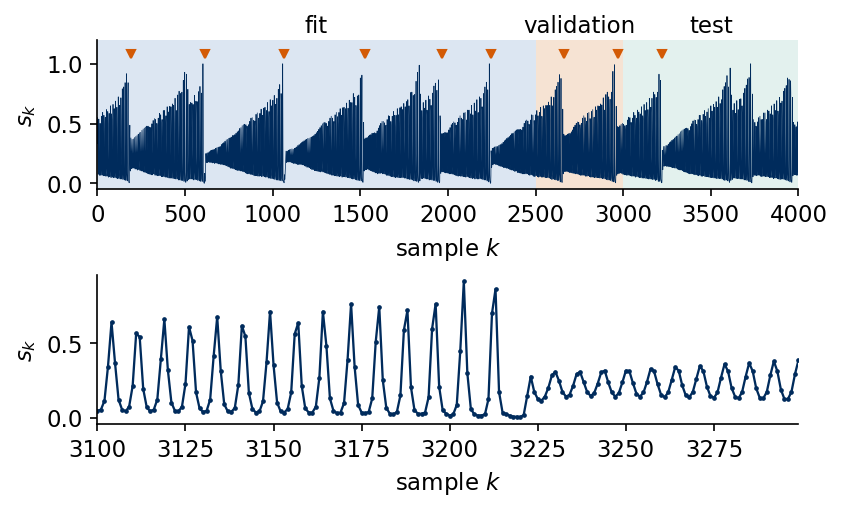

In [3]:
env = np.array([s_sf[max(0, k - 8):k + 9].max() for k in range(N_SAMPLES)])     # running maximum e_k
collapse = [k for k in range(25, N_SAMPLES) if env[k] < 0.5 * env[k - 24] and not env[k - 1] < 0.5 * env[k - 25]]
print("collapses at k =", collapse, "| intervals:", np.diff(collapse).tolist())
nums["collapses"] = dict(k=collapse, intervals=np.diff(collapse).tolist())

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 1, figsize=(5.5, 3.3), layout="constrained", gridspec_kw={"height_ratios": [1, 1]})
    ax = axs[0]
    ax.axvspan(0, N_TRAIN - N_VAL, color="#DCE6F2", lw=0)
    ax.axvspan(N_TRAIN - N_VAL, N_TRAIN, color="#F6E3D3", lw=0)
    ax.axvspan(N_TRAIN, N_SAMPLES, color="#E3F1EE", lw=0)
    ax.plot(np.arange(N_SAMPLES), s_sf, color=UJNavy, lw=0.35)
    ax.plot(collapse, np.full(len(collapse), 1.08), "v", color=DSOrange, ms=4)
    for x, t in ((1250, "fit"), (2750, "validation"), (3500, "test")):
        ax.text(x, 1.22, t, ha="center", va="bottom")
    ax.set_xlim(0, N_SAMPLES); ax.set_ylim(-0.05, 1.2); ax.set_ylabel("$s_k$"); ax.set_xlabel("sample $k$")
    ax = axs[1]
    kz = np.arange(3100, 3300)
    ax.plot(kz, s_sf[kz], color=UJNavy, lw=1.1, marker=".", ms=2.5)
    ax.set_xlim(kz[0], kz[-1]); ax.set_ylabel("$s_k$"); ax.set_xlabel("sample $k$")
    save(fig, "fig_lab038_santafe_signal"); plt.show()

The upper panel shows the whole record with the three blocks and the collapses (triangles), the lower panel 200 samples around the collapse near $k=3222$. A pulsation lasts only a few samples, so one period is sampled coarsely. The time scale of one pulsation is measured by the autocorrelation function of the training block,
$$\rho(m)=\frac{\sum_{k}(s_k-\bar s)(s_{k+m}-\bar s)}{\sum_k(s_k-\bar s)^2},$$
with $\bar s$ the mean of the training block. We compute it with `jnp.correlate` and check it against a direct sum in NumPy.

max |rho_JAX - rho_numpy| = 4.440892098500626e-16
first maximum of rho at m = 8 (rho = 0.759); maxima at m = [8, 15, 22, 30, 37, 44]


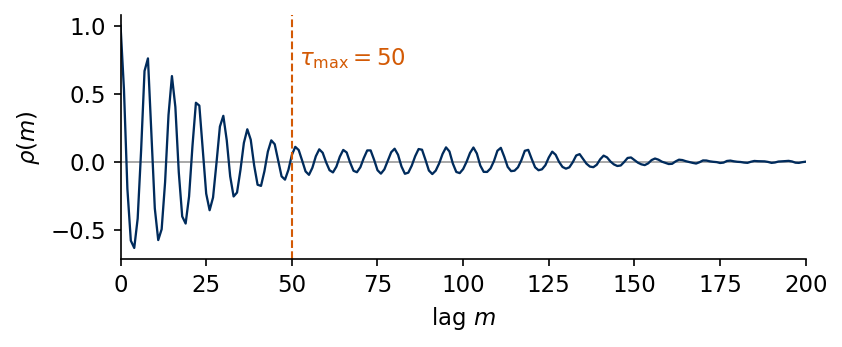

In [4]:
@jax.jit
def acf(x):
    # rho(m) for m = 0..len(x)-1, normalised by the sum of squares of the centred signal
    xc = x - x.mean()
    full = jnp.correlate(xc, xc, mode="full")[x.shape[0] - 1:]
    return full / full[0]

M_ACF = 200
rho_acf = np.asarray(acf(jnp.asarray(s_sf[:N_TRAIN])))[:M_ACF + 1]
xc = s_sf[:N_TRAIN] - s_sf[:N_TRAIN].mean()
rho_np = np.array([np.sum(xc[:N_TRAIN - m] * xc[m:]) for m in range(M_ACF + 1)]) / np.sum(xc ** 2)
print("max |rho_JAX - rho_numpy| =", np.abs(rho_acf - rho_np).max())
peaks = [m for m in range(1, M_ACF) if rho_acf[m] > rho_acf[m - 1] and rho_acf[m] >= rho_acf[m + 1]]
period = peaks[0]
print(f"first maximum of rho at m = {period} (rho = {rho_acf[period]:.3f}); maxima at m = {peaks[:6]}")
nums["acf"] = dict(period=int(period), rho_period=float(rho_acf[period]), rho_50=float(rho_acf[50]),
                   first_zero=int(np.argmax(rho_acf < 0)))

with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.2), layout="constrained")
    ax.axhline(0, color="0.6", lw=0.8)
    ax.plot(np.arange(M_ACF + 1), rho_acf, color=UJNavy, lw=1.1)
    ax.axvline(TAU_MAX, color=DSOrange, ls="--", lw=1.0)
    ax.text(TAU_MAX + 2, 0.85, r"$\tau_{\max}=50$", color=DSOrange, ha="left", va="top")
    ax.set_xlim(0, M_ACF); ax.set_xlabel("lag $m$"); ax.set_ylabel(r"$\rho(m)$")
    save(fig, "fig_lab038_santafe_acf"); plt.show()

The autocorrelation has its first maximum at the lag $m=8$ with $\rho(8)=0.759$, so one pulsation lasts about 8 samples, and further maxima follow at $m=15,22,30,37,44$. The height of the maxima decreases with the lag, and near $m=50$ the linear correlation is weak. The function measures only linear dependence, so a nonlinear model may still forecast beyond this range. The collapses found by the envelope criterion are separated by 253 to 461 samples, several times the window of 64 values. A model that reads the last 64 values therefore sees the phase and the current amplitude of the pulsations, while the time since the previous collapse is outside its window.

### Mackey–Glass signals

As a second family of signals we use the Mackey–Glass delay equation
$$\dot s(t)=\frac{\beta\,s(t-\tau_{\rm MG})}{1+s(t-\tau_{\rm MG})^{10}}-\gamma\,s(t),\qquad \beta=0.2,\quad \gamma=0.1,$$
a model of the regulation of blood-cell production in which the production rate responds to the population a time $\tau_{\rm MG}$ earlier [Mackey and Glass, Science **197**, 287 (1977), [doi:10.1126/science.267326](https://doi.org/10.1126/science.267326)]. The delay controls the dynamics. For $\tau_{\rm MG}=15$ the solution settles on a limit cycle, for $\tau_{\rm MG}=25$ it is weakly chaotic and for $\tau_{\rm MG}=35$ the chaos is developed. The equation is integrated by the fourth-order Runge–Kutta method with the step $h=0.1$, the delayed value at half steps is interpolated linearly, the history is constant, $s=1.2$ on $[-\tau_{\rm MG},0]$, the first 3000 steps are discarded, and every tenth point is kept, so the sampling interval is one time unit. The signals are rescaled to $[0,1]$ with their first 2500 samples, in the same way as the laser.

MG15: test range [0.000, 1.000], first maximum of rho at m = 45 (rho = 0.794)
MG25: test range [-0.035, 1.027], first maximum of rho at m = 85 (rho = 0.308)
MG35: test range [0.004, 1.005], first maximum of rho at m = 121 (rho = 0.459)


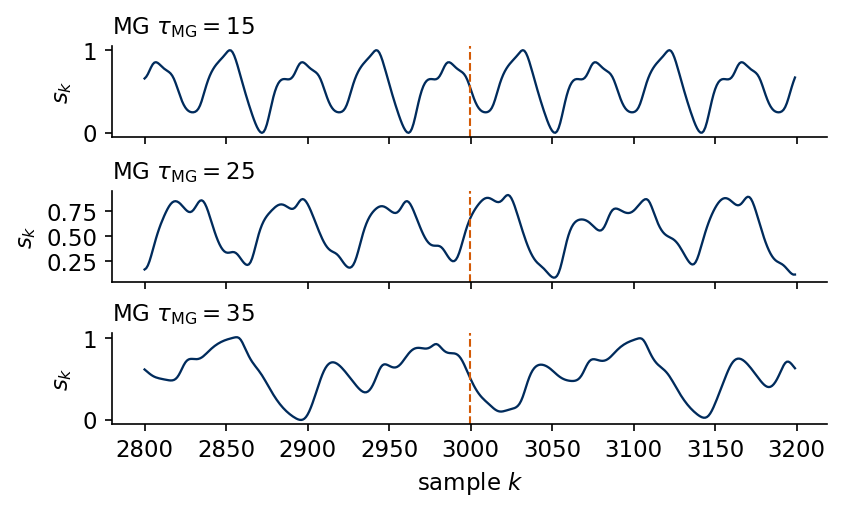

In [5]:
# Mackey-Glass: dx/dt = beta x(t-tau)/(1+x(t-tau)^n) - gamma x, beta=0.2, gamma=0.1, n=10;
# RK4 with h=0.1, the delayed value at half steps by linear interpolation, constant history
# x=1.2 on [-tau, 0], first 3000 fine steps discarded, every 10th point kept (unit sampling).
def mackey_glass(tau, n_samples, h=0.1, x0=1.2, transient=3000, every=10,
                 beta=0.2, gamma=0.1, n=10):
    lag = int(round(tau / h))
    f = lambda x, xd: beta * xd / (1.0 + xd**n) - gamma * x
    def step(buf, _):
        # buf = (x[i-lag], ..., x[i]) : the delay window, length lag+1
        x, xd0, xd1 = buf[-1], buf[0], buf[1]
        xdh = 0.5 * (xd0 + xd1)
        k1 = f(x, xd0); k2 = f(x + 0.5*h*k1, xdh); k3 = f(x + 0.5*h*k2, xdh); k4 = f(x + h*k3, xd1)
        xn = x + h/6.0*(k1 + 2*k2 + 2*k3 + k4)
        return jnp.concatenate([buf[1:], xn[None]]), xn
    n_steps = transient + n_samples * every
    _, xs = jax.lax.scan(step, jnp.full(lag + 1, x0), None, length=n_steps)
    x = np.concatenate([np.full(lag + 1, x0), np.asarray(xs)])
    return x[transient::every][:n_samples]

SIGNALS = ["SantaFe", "MG15", "MG25", "MG35"]
LABEL = {"SantaFe": "Santa Fe laser", "MG15": r"MG $\tau_{\rm MG}=15$", "MG25": r"MG $\tau_{\rm MG}=25$",
         "MG35": r"MG $\tau_{\rm MG}=35$"}
sig = {"SantaFe": s_sf}
for tau_mg in (15, 25, 35):
    sig[f"MG{tau_mg}"] = rescale01(mackey_glass(tau_mg, N_SAMPLES))
for name in SIGNALS[1:]:
    s = sig[name]
    acf_mg = np.asarray(acf(jnp.asarray(s[:N_TRAIN])))
    pk = [m for m in range(1, 300) if acf_mg[m] > acf_mg[m - 1] and acf_mg[m] >= acf_mg[m + 1]]
    nums.setdefault("mg_acf", {})[name] = dict(first_max=int(pk[0]), rho_first_max=float(acf_mg[pk[0]]))
    print(f"{name}: test range [{s[N_TRAIN:].min():.3f}, {s[N_TRAIN:].max():.3f}],"
          f" first maximum of rho at m = {pk[0]} (rho = {acf_mg[pk[0]]:.3f})")

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(3, 1, figsize=(5.5, 3.3), sharex=True, layout="constrained")
    for ax, name in zip(axs, SIGNALS[1:]):
        ax.plot(np.arange(2800, 3200), sig[name][2800:3200], color=UJNavy, lw=1.1)
        ax.axvline(N_TRAIN - 0.5, color=DSOrange, ls="--", lw=1.0)
        ax.set_ylabel("$s_k$"); ax.set_title(LABEL[name], loc="left")
    axs[-1].set_xlabel("sample $k$")
    save(fig, "fig_lab038_mg_signals"); plt.show()

The three regimes look different already over 400 samples. At $\tau_{\rm MG}=15$ the signal repeats a cycle made of two oscillations of different height, and the autocorrelation of the training block has its first maximum at $m=45$ with $\rho=0.794$, after one oscillation. At $\tau_{\rm MG}=25$ and $\tau_{\rm MG}=35$ the oscillations no longer repeat, the first maxima of the autocorrelation lie at $m=85$ and $m=121$ and reach only 0.308 and 0.459. All three signals are smooth on the scale of one sample, unlike the laser, whose pulsation lasts 8 samples. The test block of $\tau_{\rm MG}=25$ slightly exceeds the training range, with values from $-0.035$ to $1.027$.

### Forecasting protocol

A forecast is made at an origin $k$ from the past $s_k,s_{k-1},\dots$ and returns all leads $\tau=1,\dots,50$ at once. This is direct forecasting, one output per lead, and the model never sees its own predictions. Every model of this notebook reads at most the window of the last $L=64$ values,
$$\mathbf v_k=(s_{k-L+1},\dots,s_{k-1},s_k)\in\mathbb R^{L},\qquad \mathbf y_k=(s_{k+1},\dots,s_{k+50})\in\mathbb R^{50}.$$
The origins are chosen so that no target crosses a block boundary. Fitting uses the origins $k=63,\dots,2449$ (targets inside the first 2500 samples), validation the origins $k=2499,\dots,2949$ (targets inside the validation block), and testing the origins $k=2999,\dots,3949$ (targets inside the test block). A window may reach back into an earlier block, since the inputs are past values that are known at the time of the forecast.

In [6]:
L_WIN = 64                                                        # window length L
K_FIT = np.arange(L_WIN - 1, N_TRAIN - N_VAL - TAU_MAX)           # origins 63..2449
K_VAL = np.arange(N_TRAIN - N_VAL - 1, N_TRAIN - TAU_MAX)         # origins 2499..2949
K_TEST = np.arange(N_TRAIN - 1, N_SAMPLES - TAU_MAX)              # origins 2999..3949
TAUS = np.arange(1, TAU_MAX + 1)

def windows(s, ks, L=L_WIN):
    # inputs U[i] = (s_{k-L+1}, ..., s_k) and targets Y[i] = (s_{k+1}, ..., s_{k+50}) for k = ks[i]
    U = s[ks[:, None] + np.arange(-L + 1, 1)[None, :]]
    Y = s[ks[:, None] + TAUS[None, :]]
    return U, Y

U_tmp, Y_tmp = windows(s_sf, K_TEST)
assert U_tmp.shape == (len(K_TEST), L_WIN) and Y_tmp.shape == (len(K_TEST), TAU_MAX)
assert U_tmp[0, -1] == s_sf[K_TEST[0]] and Y_tmp[0, 0] == s_sf[K_TEST[0] + 1]
assert (K_FIT + TAU_MAX).max() < N_TRAIN - N_VAL and (K_VAL + TAU_MAX).max() < N_TRAIN
assert K_TEST[0] + 1 == N_TRAIN and (K_TEST + TAU_MAX).max() == N_SAMPLES - 1
print(f"origins: fit {len(K_FIT)} ({K_FIT[0]}..{K_FIT[-1]}), validation {len(K_VAL)} ({K_VAL[0]}..{K_VAL[-1]}),"
      f" test {len(K_TEST)} ({K_TEST[0]}..{K_TEST[-1]})")
nums["protocol"] = dict(L=L_WIN, n_fit=len(K_FIT), n_val=len(K_VAL), n_test=len(K_TEST), tau_max=TAU_MAX)

origins: fit 2387 (63..2449), validation 451 (2499..2949), test 951 (2999..3949)


The assertions confirm that the first test window ends at the last training sample and that the last target is the last sample of the record. There are 2387 fitting, 451 validation and 951 test origins for every signal.

### Scores

For each lead $\tau$ we compare the predictions $\hat s_{k+\tau}$ with the true values $s_{k+\tau}$ over the $n$ test origins by the Pearson correlation coefficient
$$r(\tau)=\frac{\sum_k\big(\hat s_{k+\tau}-\overline{\hat s}_{\tau}\big)\big(s_{k+\tau}-\bar s_{\tau}\big)}{\sqrt{\sum_k\big(\hat s_{k+\tau}-\overline{\hat s}_{\tau}\big)^2\,\sum_k\big(s_{k+\tau}-\bar s_{\tau}\big)^2}},$$
where the sums run over the test origins $k$ and the bars denote the means over the same origins. The forecast capacity $C(\tau)=r(\tau)^2\in[0,1]$ is the fraction of the variance of the target that a linear rescaling of the forecast explains. Its sum over the 50 leads, the total capacity
$$C_{\rm tot}=\sum_{\tau=1}^{50}C(\tau)\le 50,$$
summarises a whole curve in one number, and the skill horizon $\tau_{1/2}$ is the first lead with $C(\tau)<0.5$. The capacity measures whether the forecast follows the shape of the future signal and does not penalise a constant offset or a wrong scale.

In [7]:
@jax.jit
def pearson_r(pred, true):
    # pred, true: (n, TAU_MAX); correlation over the n origins, one value per lead
    pc, tc = pred - pred.mean(0), true - true.mean(0)
    return jnp.sum(pc * tc, 0) / jnp.sqrt(jnp.sum(pc ** 2, 0) * jnp.sum(tc ** 2, 0))

def score(pred, true):
    # dictionary with r(tau), C(tau) = r^2, C_tot and the skill horizon tau_1/2
    r = np.asarray(pearson_r(jnp.asarray(pred, jnp.float64), jnp.asarray(true, jnp.float64)))
    C = r ** 2
    below = np.nonzero(C < 0.5)[0]
    return dict(r=r, C=C, Ctot=float(C.sum()), tau_half=int(below[0] + 1) if len(below) else None)

# check the JAX correlation against numpy on random data
rng = np.random.default_rng(0)
a, b = rng.normal(size=(500, TAU_MAX)), rng.normal(size=(500, TAU_MAX))
r_np = np.array([np.corrcoef(a[:, j] + 0.5 * b[:, j], b[:, j])[0, 1] for j in range(TAU_MAX)])
print("max |r_jax - r_numpy| =", np.abs(score(a + 0.5 * b, b)["r"] - r_np).max())

max |r_jax - r_numpy| = 6.106226635438361e-16


On random data the JAX correlation agrees with the NumPy coefficient to $10^{-15}$, the round-off of float64 arithmetic.
<hr/>
## 2. Baselines

Persistence repeats the last value, $\hat s_{k+\tau}=s_k$. It needs no fitting and sets the floor that any model must beat. The direct autoregressive model of order $p$ (AR) and the nonlinear vector autoregression (NVAR) are ridge regressions on features of the delay vector $\mathbf d_k=(s_k,s_{k-1},\dots,s_{k-p+1})$,
$$\hat{\mathbf y}_k=W^\top\boldsymbol\phi(\mathbf d_k)+\mathbf b,\qquad \boldsymbol\phi_{\rm AR}=\mathbf d_k,\qquad \boldsymbol\phi_{\rm NVAR}=\big(\mathbf d_k,\ \{s_{k-i}s_{k-j}\}_{0\le i\le j<p}\big),$$
where $W$ has one column per lead and NVAR has $p+p(p+1)/2$ features [Gauthier *et al.*, Nat. Commun. **12**, 5564 (2021), [doi:10.1038/s41467-021-25801-2](https://doi.org/10.1038/s41467-021-25801-2)]. Ridge regression minimises $\sum_k\|\hat{\mathbf y}_k-\mathbf y_k\|^2+\beta\|W\|^2$. With centred features $\Phi_c$ and centred targets $Y_c$ the solution is
$$W=(\Phi_c^\top\Phi_c+\beta I)^{-1}\Phi_c^\top Y_c,\qquad \mathbf b=\bar{\mathbf y}-W^\top\bar{\boldsymbol\phi},$$
so the intercept $\mathbf b$ is not penalised. The order $p$ and the ridge strength $\beta$ are chosen by the largest $C_{\rm tot}$ on the validation origins.

In [8]:
def ridge_fit(F, Y, beta):
    # centred ridge regression, F: (n, d) features, Y: (n, m) targets -> W (d, m), b (m,)
    fm, ym = F.mean(0), Y.mean(0)
    Fc, Yc = F - fm, Y - ym
    W = jnp.linalg.solve(Fc.T @ Fc + beta * jnp.eye(F.shape[1]), Fc.T @ Yc)
    return W, ym - fm @ W

def delay_features(s, ks, p):
    # rows (s_k, s_{k-1}, ..., s_{k-p+1})
    return s[ks[:, None] - np.arange(p)[None, :]]

def nvar_features(s, ks, p):
    # delay vector and all quadratic monomials s_{k-i} s_{k-j}, i <= j
    d = delay_features(s, ks, p)
    iu, ju = np.triu_indices(p)
    return np.concatenate([d, d[:, iu] * d[:, ju]], axis=1)

GRID_BETA = (1e-8, 1e-6, 1e-4, 1e-2, 1.0)
GRID_P = {"AR": (4, 8, 16, 24, 32, 48, 64), "NVAR": (2, 4, 8, 12, 16, 24, 32)}
FEATS = {"AR": delay_features, "NVAR": nvar_features}

def ridge_model(s, kind):
    # choose (p, beta) by validation C_tot, return the test predictions and the chosen setting
    _, Yf = windows(s, K_FIT); _, Yv = windows(s, K_VAL); _, Yt = windows(s, K_TEST)
    best = (-1.0, None, None)
    for p in GRID_P[kind]:
        Ff, Fv = FEATS[kind](s, K_FIT, p), FEATS[kind](s, K_VAL, p)
        for beta in GRID_BETA:
            W, b = ridge_fit(Ff, Yf, beta)
            ctot = score(Fv @ W + b, Yv)["Ctot"]
            if ctot > best[0]:
                best = (ctot, p, beta)
    _, p, beta = best
    Ff, Ft = FEATS[kind](s, K_FIT, p), FEATS[kind](s, K_TEST, p)
    W, b = ridge_fit(Ff, Yf, beta)
    return dict(pred=np.asarray(Ft @ W + b), p=p, beta=beta, n_feat=Ff.shape[1], **score(Ft @ W + b, Yt))

res = {name: {} for name in SIGNALS}       # res[signal][model] = scores and predictions on the test origins
for name in SIGNALS:
    s = sig[name]
    U_test, Y_test = windows(s, K_TEST)
    res[name]["persistence"] = dict(pred=np.repeat(U_test[:, -1:], TAU_MAX, 1), **score(np.repeat(U_test[:, -1:], TAU_MAX, 1), Y_test))
    for kind in ("AR", "NVAR"):
        res[name][kind] = ridge_model(s, kind)
    print(f"{name:8s} " + " | ".join(
        f"{m} C_tot {res[name][m]['Ctot']:5.1f}, tau_1/2 {res[name][m]['tau_half'] or '>50'}"
        + (f" (p = {res[name][m]['p']}, beta = {res[name][m]['beta']:.0e})" if m != "persistence" else "")
        for m in ("persistence", "AR", "NVAR")))
res_sf = res["SantaFe"]

SantaFe  persistence C_tot   5.5, tau_1/2 1 | AR C_tot  16.5, tau_1/2 16 (p = 64, beta = 1e+00) | NVAR C_tot  34.7, tau_1/2 42 (p = 32, beta = 1e-02)


MG15     persistence C_tot  19.5, tau_1/2 6 | AR C_tot  49.8, tau_1/2 >50 (p = 64, beta = 1e-08) | NVAR C_tot  50.0, tau_1/2 >50 (p = 32, beta = 1e-08)


MG25     persistence C_tot  13.3, tau_1/2 8 | AR C_tot  33.1, tau_1/2 42 (p = 64, beta = 1e-08) | NVAR C_tot  45.5, tau_1/2 >50 (p = 32, beta = 1e-08)


MG35     persistence C_tot  11.8, tau_1/2 10 | AR C_tot  38.0, tau_1/2 >50 (p = 64, beta = 1e-08) | NVAR C_tot  48.6, tau_1/2 >50 (p = 32, beta = 1e-08)


The table separates the signals clearly. On Santa Fe persistence gives $C_{\rm tot}=5.5$ and is useless beyond the first lead, AR reaches 16.5 with $\tau_{1/2}=16$, and the quadratic features of NVAR double this to 34.7 with $\tau_{1/2}=42$. On the limit cycle of Mackey–Glass at $\tau_{\rm MG}=15$ the linear AR model already reaches 49.8 and NVAR 50.0, the maximum. A periodic signal needs no nonlinear features. On the chaotic signals AR reaches 33.1 ($\tau_{\rm MG}=25$) and 38.0 ($\tau_{\rm MG}=35$), and NVAR raises this to 45.5 and 48.6. The validation search chose the largest orders of the grids, $p=64$ for AR and $p=32$ for NVAR, on all four signals.

The same ridge regressions with scikit-learn give the same predictions, since `Ridge` with `fit_intercept=True` also centres the data and leaves the intercept unpenalised.

In [9]:
_, Yf = windows(s_sf, K_FIT)
for kind in ("AR", "NVAR"):
    p, beta = res_sf[kind]["p"], res_sf[kind]["beta"]
    sk = SkRidge(alpha=beta, fit_intercept=True).fit(FEATS[kind](s_sf, K_FIT, p), Yf)
    diff = np.abs(sk.predict(FEATS[kind](s_sf, K_TEST, p)) - res_sf[kind]["pred"]).max()
    print(f"{kind}(p={p}): max |prediction JAX - prediction scikit-learn| = {diff:.2e}")

AR(p=64): max |prediction JAX - prediction scikit-learn| = 1.44e-15
NVAR(p=32): max |prediction JAX - prediction scikit-learn| = 2.06e-12


For the Santa Fe laser the predictions of the two implementations agree to $10^{-15}$ for AR and to $10^{-12}$ for NVAR. Both differences are round-off, the larger one coming from the 560 nearly collinear quadratic features of NVAR.

### Multilayer perceptron and the training loop

A one-hidden-layer perceptron (MLP) on the window $\mathbf v_k$ computes
$$\hat{\mathbf y}_k=W_2\tanh(W_1\mathbf v_k+\mathbf b_1)+\mathbf b_2,\qquad W_1\in\mathbb R^{n_{\rm hid}\times L},\ W_2\in\mathbb R^{50\times n_{\rm hid}},$$
with $n_{\rm hid}=64$ hidden units. It sees the same 64 values as the recurrent network below but treats them as one vector, so it has no notion of their order in time. Its features are learned, unlike the fixed monomials of NVAR. It is the reference for the question whether processing the window as a sequence helps.

The MLP and the RNN are trained by one function. The training set consists of the windows $(\mathbf v_k,\mathbf y_k)$ for the fitting origins, an array of shape $(n_{\rm fit},L,1)$ of inputs and $(n_{\rm fit},50)$ of targets. We shuffle them at every epoch and cut them into minibatches of $B=128$ windows. The loss is the mean-square error over the minibatch and all 50 leads,
$$\mathcal L=\frac{1}{50\,B}\sum_{k\in\text{batch}}\|\hat{\mathbf y}_k-\mathbf y_k\|^2 .$$
The Adam optimiser with learning rate $5\times10^{-3}$ updates the weights [Kingma and Ba, ICLR (2015), [arXiv:1412.6980](https://arxiv.org/abs/1412.6980)], and before every update the gradient is clipped to Euclidean norm 1. After every epoch the loss on the validation windows is computed, the parameters with the lowest validation loss are kept, and training stops when it has not improved for 20 epochs, at most after 250 epochs. Clipping and early stopping are discussed with the RNN in Section 5.

`nnx.split` separates a model into its structure (`graphdef`) and its parameters, which makes the loss a pure function of the parameters. `jax.value_and_grad` returns loss and gradient, `optax.chain(clip_by_global_norm, adam)` turns the gradient into an update, and one `jax.lax.scan` over the minibatches forms an epoch that `jax.jit` compiles once. The function also records the gradient norm of every update before clipping.

In [10]:
BATCH, LR, CLIP, MAX_EPOCHS, PATIENCE = 128, 5e-3, 1.0, 250, 20

def n_params(model):
    return int(sum(x.size for x in jax.tree.leaves(nnx.state(model, nnx.Param))))

def fit_network(model, data, seed=0, clip=CLIP, epochs=MAX_EPOCHS, patience=PATIENCE):
    # data = (U_fit, Y_fit, U_val, Y_val), inputs of shape (n, L, 1), float32; clip=None switches clipping off
    Uf, Yf, Uv, Yv = data
    graphdef, params, rest = nnx.split(model, nnx.Param, ...)
    tx = optax.chain(optax.clip_by_global_norm(clip), optax.adam(LR)) if clip else optax.adam(LR)
    opt_state = tx.init(params)
    n = Uf.shape[0]; n_batches = n // BATCH

    def loss_fn(p, U, Y):
        return jnp.mean((nnx.merge(graphdef, p, rest)(U) - Y) ** 2)

    @jax.jit
    def epoch(p, opt_state, key):
        idx = jax.random.permutation(key, n)[: n_batches * BATCH].reshape(n_batches, BATCH)
        def step(carry, ib):
            p, opt_state = carry
            loss, g = jax.value_and_grad(loss_fn)(p, Uf[ib], Yf[ib])
            gnorm = optax.global_norm(g)                  # norm before clipping
            upd, opt_state = tx.update(g, opt_state, p)
            return (optax.apply_updates(p, upd), opt_state), (loss, gnorm)
        (p, opt_state), (losses, gnorms) = jax.lax.scan(step, (p, opt_state), idx)
        return p, opt_state, losses.mean(), gnorms, loss_fn(p, Uv, Yv)

    key = jax.random.key(seed)
    hist = dict(train=[], val=[], gnorm=[])
    best_val, best_params, best_ep, t0 = np.inf, params, 0, time.time()
    for ep in range(epochs):
        key, sub = jax.random.split(key)
        params, opt_state, l_tr, gn, l_va = epoch(params, opt_state, sub)
        hist["train"].append(float(l_tr)); hist["val"].append(float(l_va)); hist["gnorm"].append(np.asarray(gn))
        if float(l_va) < best_val:
            best_val, best_params, best_ep = float(l_va), params, ep
        elif ep - best_ep >= patience:
            break
    hist = dict(train=np.array(hist["train"]), val=np.array(hist["val"]), gnorm=np.concatenate(hist["gnorm"]))
    hist.update(best_epoch=best_ep + 1, epochs_run=ep + 1, time=time.time() - t0, best_val=best_val,
                steps_per_epoch=n_batches)
    return nnx.merge(graphdef, best_params, rest), hist

def net_data(s, L=L_WIN):
    # float32 windows (n, L, 1) and targets (n, 50) for fitting, validation and test origins
    out = []
    for ks in (K_FIT, K_VAL, K_TEST):
        U, Y = windows(s, ks, L)
        out += [jnp.asarray(U[..., None], jnp.float32), jnp.asarray(Y, jnp.float32)]
    return out

def predict(model, U):
    return np.asarray(model(U), np.float64)

data = {name: net_data(sig[name]) for name in SIGNALS}
data_sf = data["SantaFe"]
Y_T = {name: np.asarray(data[name][5], np.float64) for name in SIGNALS}       # test targets
Y_TEST = Y_T["SantaFe"]

The function `fit_network` returns the parameters with the lowest validation loss together with the history of the training loss, the validation loss and the gradient norms, and `net_data` prepares the float32 windows of every signal. The MLP module below flattens the window and applies the two layers. `nnx.Linear` initialises each weight matrix with the LeCun normal distribution, variance $1/n_{\rm in}$, and the biases with zeros. On Santa Fe we train it with three seeds, which fix the initial weights and the order of the minibatches, and on the Mackey–Glass signals with seed 0.

In [11]:
N_MLP = 64

class MLP(nnx.Module):
    def __init__(self, L, n_hid, n_out, *, rngs):
        self.l1 = nnx.Linear(L, n_hid, rngs=rngs)        # W_1, b_1
        self.l2 = nnx.Linear(n_hid, n_out, rngs=rngs)    # W_2, b_2
    def __call__(self, U):
        # U: (batch, L, 1) -> (batch, 50)
        return self.l2(jnp.tanh(self.l1(U[..., 0])))

SEEDS = (0, 1, 2)
mlp_runs = {}
for seed in SEEDS:
    m, h = fit_network(MLP(L_WIN, N_MLP, TAU_MAX, rngs=nnx.Rngs(seed)), data_sf[:4], seed=seed)
    mlp_runs[seed] = dict(model=m, hist=h, **score(predict(m, data_sf[4]), Y_TEST))
    print(f"MLP seed {seed}: {h['epochs_run']} epochs (best {h['best_epoch']}), {h['time']:.1f} s,"
          f" test C_tot = {mlp_runs[seed]['Ctot']:.1f}")
res_sf["MLP"] = mlp_runs[0]
print(f"MLP parameters: {n_params(mlp_runs[0]['model'])}")
for name in SIGNALS[1:]:
    m, h = fit_network(MLP(L_WIN, N_MLP, TAU_MAX, rngs=nnx.Rngs(0)), data[name][:4], seed=0)
    res[name]["MLP"] = dict(pred=predict(m, data[name][4]), **score(predict(m, data[name][4]), Y_T[name]))
    print(f"MLP {name}: {h['epochs_run']} epochs (best {h['best_epoch']}), test C_tot = {res[name]['MLP']['Ctot']:.1f}")
nums["mlp_seeds_Ctot"] = [mlp_runs[s_]["Ctot"] for s_ in SEEDS]

MLP seed 0: 250 epochs (best 244), 2.0 s, test C_tot = 35.3


MLP seed 1: 250 epochs (best 247), 1.8 s, test C_tot = 35.6


MLP seed 2: 250 epochs (best 245), 1.7 s, test C_tot = 36.0
MLP parameters: 7410


MLP MG15: 146 epochs (best 126), test C_tot = 50.0


MLP MG25: 250 epochs (best 241), test C_tot = 48.4


MLP MG35: 250 epochs (best 235), test C_tot = 49.5


The MLP reaches $C_{\rm tot}=35.3$, 35.6 and 36.0 on Santa Fe for the three seeds, slightly above NVAR. All three runs used the full 250 epochs, with the lowest validation loss at the epochs 244 to 247, so the MLP was still improving slowly when the training stopped. With its 64 tanh features learned from the data it reaches about the level of NVAR with its 560 fixed monomials.

<hr/>
## 3. Elman recurrent network

A recurrent network carries the history in a state vector instead of reading a window all at once. The Elman network updates its hidden state $\mathbf h_i\in\mathbb R^{n_h}$ with every new input $x_i$,
$$\mathbf h_i=\tanh\!\big(W_h\mathbf h_{i-1}+W_x x_i+\mathbf b\big),\qquad i=1,\dots,L,\qquad \mathbf h_0=0 .$$
The recurrent matrix $W_h\in\mathbb R^{n_h\times n_h}$ couples the units to their own values one step earlier, the input matrix $W_x\in\mathbb R^{n_h\times1}$ injects the scalar input, $\mathbf b\in\mathbb R^{n_h}$ is a bias and tanh acts elementwise. As a forecaster the network reads the window of origin $k$, $x_i=s_{k-L+i}$, so that $x_L=s_k$ is the newest value, and the last state is read out linearly to all leads,
$$\hat{\mathbf y}_k=W_y\mathbf h_L+\mathbf b_y,\qquad W_y\in\mathbb R^{50\times n_h},$$
where output $\tau$ is $\hat s_{k+\tau}$. Every forecast starts again from $\mathbf h_0=0$, so the network sees only the $L$ values of the window, the same information as the MLP. The two models differ in how they process it. The RNN applies the same map with the same weights to every value, in time order, while the MLP has a separate weight for every position of the window.

Elman drew the network with context units that hold a copy of the hidden layer from the previous step and feed it back through $W_h$. The drawing below shows this cell with nodes and edges. Unrolled over the window, the same cell becomes a deep feed-forward network with one layer per input value and the same weights $W_h$, $W_x$ in every layer.

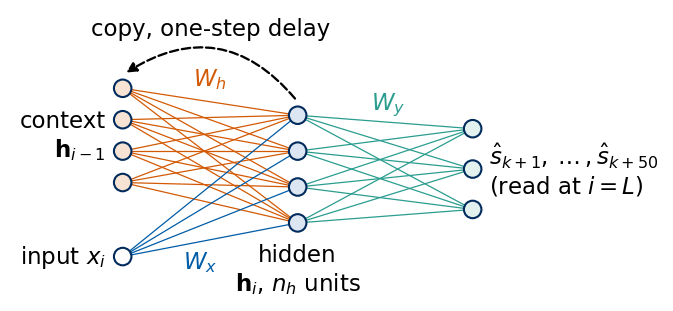

In [12]:
def draw_column(ax, x, n, y_top, y_bot, r=0.13, fc="#DCE6F2"):
    """Draw n neurons at horizontal position x, evenly spaced between y_top and y_bot.
    Returns the list of node centres (x, y), from top to bottom."""
    ys = np.linspace(y_top, y_bot, n) if n > 1 else np.array([(y_top + y_bot) / 2])
    for y in ys:
        ax.add_patch(Circle((x, y), r, fc=fc, ec=UJNavy, lw=1.0, zorder=3))
    return [(x, y) for y in ys]

def connect(ax, A, B, color="0.7", lw=0.6):
    """All-to-all edges from the nodes A to the nodes B (a dense weight matrix)."""
    for (x0, y0) in A:
        for (x1, y1) in B:
            ax.plot([x0, x1], [y0, y1], color=color, lw=lw, zorder=1)

C_WH, C_WX, C_WY = DSOrange, UJBlue, GREEN     # colours of the three weight matrices

with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.9))
    # left column: context units (copy of h_{i-1}) above the single input x_i
    ctx = draw_column(ax, 0.0, 4, 1.9, 0.5, fc="#F6E3D3")
    inp = draw_column(ax, 0.0, 1, -0.6, -0.6, fc="white")
    hid = draw_column(ax, 2.6, 4, 1.5, -0.1)                 # hidden units h_i (n_h of them, 4 drawn)
    out = draw_column(ax, 5.2, 3, 1.3, 0.1, fc="#E3F1EE")     # readout to the 50 leads (3 drawn)
    connect(ax, ctx, hid, color=C_WH)                       # W_h
    connect(ax, inp, hid, color=C_WX)                       # W_x
    connect(ax, hid, out, color=C_WY)                       # W_y
    # feedback: the hidden layer is copied into the context units with a delay of one step
    ax.annotate("", xy=(0.0, 2.1), xytext=(2.6, 1.7), zorder=2,
                arrowprops=dict(arrowstyle="-|>", connectionstyle="arc3,rad=0.45", color="k", lw=1.1, ls="--", mutation_scale=10))
    ax.text(1.3, 2.62, "copy, one-step delay", ha="center", va="bottom")
    ax.text(1.3, 1.85, "$W_h$", color=C_WH, ha="center", va="bottom")
    ax.text(1.15, -0.5, "$W_x$", color=C_WX, ha="center", va="top")
    ax.text(3.95, 1.45, "$W_y$", color=C_WY, ha="center", va="bottom")
    ax.text(-0.25, 1.2, "context\n" + r"$\mathbf{h}_{i-1}$", ha="right", va="center")
    ax.text(-0.25, -0.6, "input $x_i$", ha="right", va="center")
    ax.text(2.6, -0.4, "hidden\n" + r"$\mathbf{h}_i$, $n_h$ units", ha="center", va="top")
    ax.text(5.45, 0.7, r"$\hat s_{k+1},\dots,\hat s_{k+50}$" + "\n(read at $i=L$)", ha="left", va="center")
    ax.set_xlim(-1.6, 7.9); ax.set_ylim(-1.0, 3.0); ax.set_aspect("equal"); ax.axis("off")
    save(fig, "fig_lab038_elman_cell"); plt.show()

In the drawing the left column holds the context units, a copy of the hidden state of the previous step, above the single input node. Orange edges are the entries of $W_h$, blue edges those of $W_x$ and green edges those of the readout $W_y$. The dashed arrow closes the loop, since after every step the hidden layer is copied into the context units. The readout is evaluated only once, after the last value of the window. Drawing one copy of the cell per step removes the loop and gives the unrolled network.

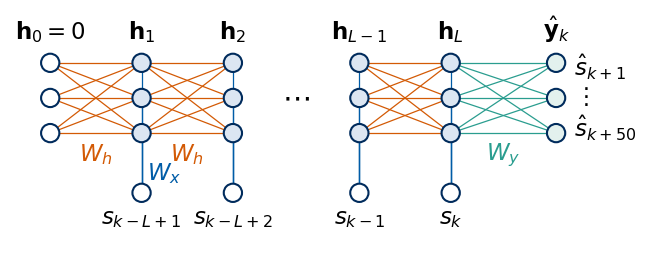

In [13]:
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.5))
    # hidden columns h_0, h_1, h_2, ..., h_{L-1}, h_L (3 units drawn each), inputs below, readout at the end
    xs = [0.0, 1.3, 2.6, 4.4, 5.7]
    tags = [r"$\mathbf{h}_0=0$", r"$\mathbf{h}_1$", r"$\mathbf{h}_2$", r"$\mathbf{h}_{L-1}$", r"$\mathbf{h}_L$"]
    xin = [None, r"$s_{k-L+1}$", r"$s_{k-L+2}$", r"$s_{k-1}$", r"$s_k$"]
    cols = [draw_column(ax, x, 3, 1.5, 0.5, fc="white" if i == 0 else "#DCE6F2") for i, x in enumerate(xs)]
    for i, x in enumerate(xs):
        ax.text(x, 1.75, tags[i], ha="center", va="bottom")
        if xin[i] is not None:
            node = draw_column(ax, x, 1, -0.35, -0.35, fc="white")
            connect(ax, node, cols[i], color=C_WX)
            ax.text(x, -0.55, xin[i], ha="center", va="top")
    for a, b in ((0, 1), (1, 2), (3, 4)):
        connect(ax, cols[a], cols[b], color=C_WH)
    ax.text(3.5, 1.0, r"$\cdots$", ha="center", va="center", fontsize=14)
    outn = draw_column(ax, 7.2, 3, 1.5, 0.5, fc="#E3F1EE")
    connect(ax, cols[-1], outn, color=C_WY)
    ax.text(7.2, 1.75, r"$\hat{\mathbf{y}}_k$", ha="center", va="bottom")
    ax.text(7.45, 1.0, r"$\hat s_{k+1}$" + "\n" + r"$\vdots$" + "\n" + r"$\hat s_{k+50}$", ha="left", va="center")
    ax.text(0.65, 0.38, "$W_h$", color=C_WH, ha="center", va="top")
    ax.text(1.95, 0.38, "$W_h$", color=C_WH, ha="center", va="top")
    ax.text(6.45, 0.38, "$W_y$", color=C_WY, ha="center", va="top")
    ax.text(1.38, -0.08, "$W_x$", color=C_WX, ha="left", va="center")
    ax.set_xlim(-0.5, 8.6); ax.set_ylim(-1.05, 2.1); ax.set_aspect("equal"); ax.axis("off")
    save(fig, "fig_lab038_rnn_unrolled"); plt.show()

The orange edges carry the same matrix $W_h$ between every pair of neighbouring columns, and the blue edges the same $W_x$ at every input. Depth in this network is time. A window of $L=64$ values makes a network with 64 hidden layers, although it has only $n_h^2+2n_h$ recurrent parameters.

### RNN implementation in JAX

The cell is an `nnx.Module` with the signature of the library cells, `cell(h, x_i) -> (h, h)`. It acts on a batch, so $x_i$ has shape $(B,1)$ and $\mathbf h$ shape $(B,n_h)$. A second module `Recurrent` runs the cell over the window with `jax.lax.scan`, which compiles the loop over the $L$ steps once, and applies the readout to the last state. The window has shape $(B,L,1)$ and scan iterates over the leading axis, so we swap the batch and time axes before the loop. In `nnx.Linear` a matrix acts from the right, $\mathbf h\mapsto\mathbf h K$, so the stored kernel is $K=W_h^\top$.

The input matrix is initialised with the LeCun normal distribution and the recurrent matrix with a random orthogonal matrix, as in the library cell. All singular values of an orthogonal matrix are 1, so at initialisation $W_h$ neither stretches nor shrinks the state. The argument `rho` multiplies this matrix, which sets all its singular values and its spectral radius to $\rho$. We use it in Sections 4 and 5 to put an untrained network into a contracting or an expanding regime.

In [14]:
orthogonal = nnx.initializers.orthogonal()

class RNNCell(nnx.Module):
    # h_i = tanh(W_x x_i + b + W_h h_{i-1}); kernels act from the right, Wh.kernel = W_h^T
    def __init__(self, n_x, n_h, *, rngs, rho=1.0):
        self.n_h = n_h
        self.Wx = nnx.Linear(n_x, n_h, rngs=rngs)                                   # W_x and b
        self.Wh = nnx.Linear(n_h, n_h, use_bias=False, kernel_init=orthogonal, rngs=rngs)
        if rho != 1.0:
            self.Wh.kernel[...] = rho * self.Wh.kernel[...]                         # all singular values = rho
    def init_carry(self, B, dtype):
        return jnp.zeros((B, self.n_h), dtype)
    def __call__(self, h, x):
        h = jnp.tanh(self.Wx(x) + self.Wh(h))
        return h, h

class Recurrent(nnx.Module):
    # the cell run over the window from h_0 = 0, linear readout of the last hidden state to the 50 leads
    def __init__(self, cell, n_h, n_out, *, rngs):
        self.cell = cell
        self.head = nnx.Linear(n_h, n_out, rngs=rngs)    # W_y, b_y
    def hidden_states(self, V):
        # V: (B, L, 1) -> all hidden states (L, B, n_h)
        carry = self.cell.init_carry(V.shape[0], V.dtype)
        _, hs = jax.lax.scan(lambda c, x: self.cell(c, x), carry, jnp.swapaxes(V, 0, 1))
        return hs
    def __call__(self, V):
        return self.head(self.hidden_states(V)[-1])

N_H = 32
def make_rnn(seed, n_h=N_H, rho=1.0):
    rngs = nnx.Rngs(seed)
    return Recurrent(RNNCell(1, n_h, rngs=rngs, rho=rho), n_h, TAU_MAX, rngs=rngs)

rnn0 = make_rnn(0)
print("output shape", rnn0(data_sf[0][:4]).shape, "| parameters", n_params(rnn0))

output shape (4, 50) | parameters 2738


The untrained forecaster maps a batch of four windows to four rows of 50 outputs and has 2738 parameters, a number we derive below.

### flax nnx.SimpleCell

Flax provides the same cell as `nnx.SimpleCell` and the loop over time as `nnx.RNN`. We copy the library weights into our cell, run both on the same random sequence of length 64 and batch size 8, and then run the whole forecaster once with our `Recurrent` module and once with `nnx.RNN` around a library cell that holds the same weights.

In [15]:
def run_cell(cell, carry, S):
    # S: (L, B, n_x) -> hidden states (L, B, n_h)
    return jax.lax.scan(lambda c, x: cell(c, x), carry, S)[1]

S_chk = jax.random.uniform(jax.random.key(3), (64, 8, 1), jnp.float32)
lib = nnx.SimpleCell(1, N_H, rngs=nnx.Rngs(1)); own = RNNCell(1, N_H, rngs=nnx.Rngs(2))
own.Wx.kernel[...] = lib.dense_i.kernel[...]; own.Wx.bias[...] = lib.dense_i.bias[...]
own.Wh.kernel[...] = lib.dense_h.kernel[...]
h0 = jnp.zeros((8, N_H), jnp.float32)
print("cell:       max |h_own - h_flax| =", float(jnp.abs(run_cell(own, h0, S_chk) - run_cell(lib, h0, S_chk)).max()))

lib = nnx.SimpleCell(1, N_H, rngs=nnx.Rngs(1))               # library cell with the weights of our forecaster
lib.dense_i.kernel[...] = rnn0.cell.Wx.kernel[...]; lib.dense_i.bias[...] = rnn0.cell.Wx.bias[...]
lib.dense_h.kernel[...] = rnn0.cell.Wh.kernel[...]
loop = nnx.RNN(lib, return_carry=True)                       # batch-major input (B, L, 1)
h_last_lib, _ = loop(data_sf[0][:8], initial_carry=jnp.zeros((8, N_H), jnp.float32))
y_lib = rnn0.head(h_last_lib)
print("forecaster: max |y_own - y_nnx.RNN| =", float(jnp.abs(rnn0(data_sf[0][:8]) - y_lib).max()))

cell:       max |h_own - h_flax| = 0.0


forecaster: max |y_own - y_nnx.RNN| = 0.0


Both differences are exactly zero. Our cell and the library cell perform the same float32 operations in the same order, so the agreement holds to the last bit.

The recurrence has $n_h^2$ weights in $W_h$, $n_h$ in $W_x$ and $n_h$ in $\mathbf b$, and the readout adds $50(n_h+1)$,
$$P_{\rm RNN}=n_h^2+2n_h+50(n_h+1).$$
For $n_h=32$ this gives $1088+1650=2738$ parameters, fewer than the $64\cdot64+64+50\cdot65=7410$ of the MLP. `nnx.tabulate` lists the submodules with the shapes of their parameters and outputs for a batch of two windows.

In [16]:
P_formula = lambda n_h: n_h ** 2 + 2 * n_h + TAU_MAX * (n_h + 1)
for n_h in (8, 32, 128):
    assert n_params(make_rnn(0, n_h)) == P_formula(n_h)
nums["params"] = dict(RNN=n_params(rnn0), MLP=n_params(mlp_runs[0]["model"]))
print(f"RNN n_h = 32: formula {P_formula(32)}, module {n_params(rnn0)} | MLP: {nums['params']['MLP']}")
print(nnx.tabulate(rnn0, data_sf[0][:2], depth=2, console_kwargs={"width": 120}))

RNN n_h = 32: formula 2738, module 2738 | MLP: 7410


                                      Recurrent Summary                                       
┏━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ path            ┃ type      ┃ inputs           ┃ outputs          ┃ Param                  ┃
┡━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ hidden_states   │ Recurrent │ float32[2,64,1]  │ float32[64,2,32] │ 2,738 (11.0 KB)        │
├─────────────────┼───────────┼──────────────────┼──────────────────┼────────────────────────┤
│ cell/init_carry │ RNNCell   │ - 2              │ float32[2,32]    │ 1,088 (4.4 KB)         │
│                 │           │ - dtype(float32) │                  │                        │
├─────────────────┼───────────┼──────────────────┼──────────────────┼────────────────────────┤
│ cell            │ RNNCell   │ - float32[2,32]  │ - float32[2,32]  │ 1,088 (4.4 KB)         │
│                 │           │ - float32[2,1]   │ - float32[2,32]  │                        │
├─────────────────┼───────────┼──────────────────┼──────────────────┼────────────────────────┤
│ cell/Wx         │ Linear    │ float32[2,1]     │ float32[2,32]    │ bias: float32[32]      │
│                 │           │                  │                  │ kernel: float32[1,32]  │
│                 │           │                  │                  │                        │
│                 │           │                  │                  │ 64 (256 B)             │
├─────────────────┼───────────┼──────────────────┼──────────────────┼────────────────────────┤
│ cell/Wh         │ Linear    │ float32[2,32]    │ float32[2,32]    │ kernel: float32[32,32] │
│                 │           │                  │                  │                        │
│                 │           │                  │                  │ 1,024 (4.1 KB)         │
├─────────────────┼───────────┼──────────────────┼──────────────────┼────────────────────────┤
│ head            │ Linear    │ float32[2,32]    │ float32[2,50]    │ bias: float32[50]      │
│                 │           │                  │                  │ kernel: float32[32,50] │
│                 │           │                  │                  │                        │
│                 │           │                  │                  │ 1,650 (6.6 KB)         │
├─────────────────┼───────────┼──────────────────┼──────────────────┼────────────────────────┤
│                 │           │                  │            Total │ 2,738 (11.0 KB)        │
└─────────────────┴───────────┴──────────────────┴──────────────────┴────────────────────────┘
                                                                                              
                              Total Parameters: 2,738 (11.0 KB)                               

The table lists the cell with its two linear maps, `Wx` with a kernel of shape $(1,32)$ and a bias of 32 entries and `Wh` with a kernel of shape $(32,32)$ and no bias, and the readout `head` with a kernel of shape $(32,50)$ and 50 biases. The totals agree with the formula. The output shapes refer to one call of each submodule, so the cell appears with the shape of a single step.

<hr/>
## 4. Backpropagation through time

Gradient descent needs the derivative of the loss with respect to $W_h$, which enters every step of the unrolled network. The chain rule applied to the unrolled network is backpropagation through time (BPTT) [Werbos, Proc. IEEE **78**, 1550 (1990), [doi:10.1109/5.58337](https://doi.org/10.1109/5.58337)]. For one window the loss $\ell$ depends on the parameters of the recurrence only through the last state $\mathbf h_L$. We write $\mathbf a_i=W_h\mathbf h_{i-1}+W_x x_i+\mathbf b$ for the pre-activation, $D_i=\mathrm{diag}(1-\mathbf h_i^2)$ for the derivative of tanh at step $i$, and $\boldsymbol\delta_i=\partial\ell/\partial\mathbf h_i$. The backward pass starts from $\boldsymbol\delta_L=W_y^\top\,\partial\ell/\partial\hat{\mathbf y}_k$ and runs the recursion
$$
\begin{aligned}
\mathbf g_i&=D_i\boldsymbol\delta_i, \qquad \boldsymbol\delta_{i-1}=W_h^\top\mathbf g_i, \qquad i=L,\dots,1,\\
\frac{\partial\ell}{\partial W_h}&=\sum_{i=1}^{L}\mathbf g_i\mathbf h_{i-1}^\top,\qquad \frac{\partial\ell}{\partial W_x}=\sum_{i=1}^{L}\mathbf g_i x_i,\qquad \frac{\partial\ell}{\partial\mathbf b}=\sum_{i=1}^{L}\mathbf g_i ,
\end{aligned}
$$
where $\mathbf g_i=\partial\ell/\partial\mathbf a_i$. The gradient with respect to a shared weight is the sum of its contributions from all steps. We implement this recursion with a reverse `jax.lax.scan` and compare it with `jax.grad` of the training loss, which differentiates through the forward scan automatically.

In [17]:
def bptt_grads(model, V, Y):
    # explicit BPTT for the loss mean((y_hat - y)^2) over a batch; flax convention: pre-activation = x Kx + b + h Kh
    Kx, b, Kh = model.cell.Wx.kernel[...], model.cell.Wx.bias[...], model.cell.Wh.kernel[...]
    hs = model.hidden_states(V)                                   # (L, B, n_h): h_1 .. h_L
    h_prev = jnp.concatenate([jnp.zeros_like(hs[:1]), hs[:-1]])   # h_0 .. h_{L-1}
    xs = jnp.swapaxes(V, 0, 1)                                    # (L, B, 1)
    y_hat = model.head(hs[-1])
    delta_L = (2.0 / Y.size) * (y_hat - Y) @ model.head.kernel[...].T     # dl/dh_L, shape (B, n_h)
    def back(delta, inp):
        h, hp, x = inp
        g = delta * (1.0 - h ** 2)                                # dl/da_i = D_i delta_i
        return g @ Kh.T, (hp.T @ g, x.T @ g, g.sum(0))            # delta_{i-1} = W_h^T g_i, contributions of step i
    _, (dKh, dKx, db) = jax.lax.scan(back, delta_L, (hs, h_prev, xs), reverse=True)
    return dKh.sum(0), dKx.sum(0), db.sum(0)

V_b, Y_b = data_sf[0][:128], data_sf[1][:128]
graphdef, params, rest = nnx.split(rnn0, nnx.Param, ...)
g_auto = jax.grad(lambda p: jnp.mean((nnx.merge(graphdef, p, rest)(V_b) - Y_b) ** 2))(params)
dKh, dKx, db = bptt_grads(rnn0, V_b, Y_b)
for lab, mine, ad in (("W_h", dKh, g_auto["cell"]["Wh"]["kernel"][...]), ("W_x", dKx, g_auto["cell"]["Wx"]["kernel"][...]),
                      ("b", db, g_auto["cell"]["Wx"]["bias"][...])):
    print(f"dL/d{lab:4s}: max |BPTT - jax.grad| = {float(jnp.abs(mine - ad).max()):.2e}, max |jax.grad| = {float(jnp.abs(ad).max()):.2e}")

dL/dW_h : max |BPTT - jax.grad| = 7.45e-09, max |jax.grad| = 4.07e-02
dL/dW_x : max |BPTT - jax.grad| = 5.59e-09, max |jax.grad| = 1.97e-02


dL/db   : max |BPTT - jax.grad| = 1.49e-08, max |jax.grad| = 8.89e-02


The explicit backward recursion and `jax.grad` agree to about $10^{-8}$ for gradient entries of order $10^{-2}$, the round-off of float32 arithmetic. Automatic differentiation of a `jax.lax.scan` builds this reverse loop, and in what follows we let `jax.grad` do the work.

### Vanishing and exploding gradients

Unrolling the recursion for $\boldsymbol\delta$ shows how a change of the state $m$ steps before the end reaches the last state. It passes through the product of step Jacobians
$$J(m)\equiv\frac{\partial\mathbf h_L}{\partial\mathbf h_{L-m}}=D_LW_h\,D_{L-1}W_h\cdots D_{L-m+1}W_h ,$$
and the contribution of step $L-m$ to the gradient carries this product. Every factor has a norm of at most $\|W_h\|_2$, since the entries of $D_i$ lie in $(0,1]$. If the factors shrink vectors, $\|J(m)\|$ decays exponentially in $m$ and the distant past has no influence on learning. This is the vanishing gradient problem [Bengio, Simard and Frasconi, IEEE Trans. Neural Netw. **5**, 157 (1994), [doi:10.1109/72.279181](https://doi.org/10.1109/72.279181)]. If the factors stretch vectors, the product can grow exponentially and gradients explode [Pascanu, Mikolov and Bengio, ICML (2013), [arXiv:1211.5063](https://arxiv.org/abs/1211.5063)].

We measure $\|J(m)\|_2$, the largest singular value of the product, for untrained networks with $n_h=32$ whose recurrent matrix is the orthogonal initialisation scaled to $\rho\in\{0.5,1.0,1.5\}$. All singular values of $W_h$ then equal $\rho$, so $\|J(m)\|_2\le\rho^m$. The networks are driven by Santa Fe windows, and the product is accumulated backwards from the last step, $J(m)=J(m-1)\,D_{L-m+1}W_h$. For every $\rho$ we use 10 random networks and every fourth test window, average $\log_{10}\|J(m)\|_2$ over the windows, and show the mean and the range over the networks. For one window the product is checked against `jax.jacrev` of the map $\mathbf h_{L-m}\mapsto\mathbf h_L$.

m = 10: log10 ||J||_2 accumulated = -0.307005, jax.jacrev = -0.307005


rho = 0.5: mean log10 ||J(m)||_2 at m = 10, 30, 63:   -3.14   -9.66  -20.49 | rate d ln||J||/dm (m >= 10) = -0.755 | bound ln(rho) = -0.693
rho = 1.0: mean log10 ||J(m)||_2 at m = 10, 30, 63:   -0.41   -1.66   -3.72 | rate d ln||J||/dm (m >= 10) = -0.146 | bound ln(rho) = +0.000
rho = 1.5: mean log10 ||J(m)||_2 at m = 10, 30, 63:    0.60    0.91    1.55 | rate d ln||J||/dm (m >= 10) = +0.030 | bound ln(rho) = +0.405


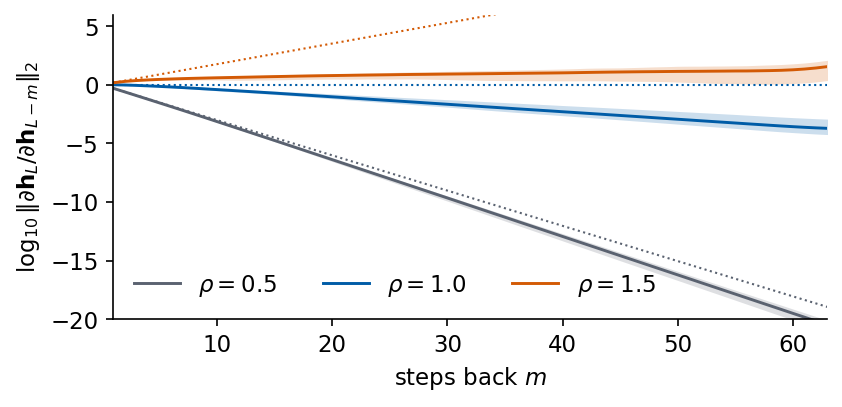

In [18]:
@jax.jit
def jac_norms_steps_back(Kh, hs):
    # hs: (L, B, n_h) hidden states of one forward pass. Returns log10 ||dh_L/dh_{L-m}||_2, shape (L-1, B), m = 1..L-1.
    # Column convention: dh_i/dh_{i-1} = D_i W_h with W_h = Kh^T.
    W = Kh.T
    def step(J, h):                            # J = J(m-1), h = h_{L-m+1}
        J = J @ ((1.0 - h ** 2)[:, :, None] * W[None])        # J(m) = J(m-1) D_{L-m+1} W_h, batched
        return J, jnp.log10(jnp.linalg.norm(J, 2, axis=(1, 2)))
    B, n = hs.shape[1], hs.shape[2]
    _, out = jax.lax.scan(step, jnp.broadcast_to(jnp.eye(n), (B, n, n)), hs[:0:-1])
    return out

def jac_profile(model, V):
    hs = model.hidden_states(V).astype(jnp.float64)
    return np.asarray(jac_norms_steps_back(model.cell.Wh.kernel[...].astype(jnp.float64), hs))

# check against automatic differentiation for one window and m = 10
V_j = data_sf[4][::4]                        # every fourth test window
m_chk, net = 10, make_rnn(0)
hs1 = net.hidden_states(V_j[:1].astype(jnp.float32))
def h_L_from(h_start):
    # run the last m_chk steps of window 0 from the state h_{L-m}
    xs = jnp.swapaxes(V_j[:1], 0, 1)[L_WIN - m_chk:]
    return jax.lax.scan(lambda h, x: net.cell(h, x), h_start, xs)[0][0]
J_ad = jax.jacrev(h_L_from)(hs1[L_WIN - m_chk - 1])[:, 0, :]
print(f"m = {m_chk}: log10 ||J||_2 accumulated = {jac_profile(net, V_j[:1])[m_chk - 1, 0]:.6f},"
      f" jax.jacrev = {np.log10(np.linalg.norm(np.asarray(J_ad, np.float64), 2)):.6f}")

RHOS, N_NETS = (0.5, 1.0, 1.5), 10
mm = np.arange(1, L_WIN)
jac_untrained = {rho: np.array([jac_profile(make_rnn(100 + i, rho=rho), V_j).mean(1) for i in range(N_NETS)]) for rho in RHOS}
nums["jac_rate"] = {}
for rho, P in jac_untrained.items():
    rate = np.polyfit(mm[mm >= 10], P.mean(0)[mm >= 10] * np.log(10), 1)[0]      # d ln||J|| / dm for m >= 10
    nums["jac_rate"][f"rho_{rho}"] = float(rate)
    print(f"rho = {rho}: mean log10 ||J(m)||_2 at m = 10, 30, 63: {P.mean(0)[9]:7.2f} {P.mean(0)[29]:7.2f} {P.mean(0)[-1]:7.2f}"
          f" | rate d ln||J||/dm (m >= 10) = {rate:+.3f} | bound ln(rho) = {np.log(rho):+.3f}")

with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.6), layout="constrained")
    for (rho, P), c in zip(jac_untrained.items(), (UJGray, UJBlue, DSOrange)):
        ax.fill_between(mm, P.min(0), P.max(0), color=c, alpha=0.2, lw=0)
        ax.plot(mm, P.mean(0), color=c, label=rf"$\rho={rho}$")
        ax.plot(mm, mm * np.log10(rho), color=c, ls=":", lw=1.0)
    ax.set_xlabel("steps back $m$"); ax.set_ylabel(r"$\log_{10}\|\partial\mathbf{h}_L/\partial\mathbf{h}_{L-m}\|_2$")
    ax.set_xlim(1, L_WIN - 1); ax.set_ylim(-20, 6); ax.legend(loc="lower left", ncol=3)
    save(fig, "fig_lab038_jacobian_untrained"); plt.show()

After a few steps every curve becomes a straight line, so the norm changes exponentially with the number of steps. For $\rho=0.5$ the norm falls at the rate $-0.755$ per step in natural logarithm, slightly faster than the bound $\ln0.5=-0.693$ (dotted line), and reaches $10^{-20.5}$ after 63 steps. The contribution of the oldest inputs to the gradient is then smaller than that of the newest ones by about twenty orders of magnitude, far below the relative precision $1.2\times10^{-7}$ of float32 arithmetic. For $\rho=1$ the bound allows no decay, and still the norm falls at the rate $-0.146$ to $10^{-3.7}$ at $m=63$. This decay comes from the factors $D_i$ alone, since every unit driven away from zero has $\tanh'<1$. For $\rho=1.5$ the norm grows, at the rate $+0.030$ far below the bound $\ln1.5=0.405$ (dotted line above the plotted range), and reaches $10^{1.55}$ at $m=63$. Large states saturate the units, which makes the factors $D_i$ small and limits the growth. The spectral radius of $W_h$ sets the bound, and the trajectory through the matrices $D_i$ sets the actual rate.

Read as an analogy with dynamical systems, the Jacobian product is the tangent propagator of the hidden-state dynamics driven by the input, and the measured rate is a finite-time estimate of its largest Lyapunov exponent. Vanishing gradients correspond to a contracting hidden dynamics and exploding gradients to an expanding one.

<hr/>
## 5. Training

We now train the RNN with $n_h=32$ on the Santa Fe windows with the training loop of Section 2.

The minibatches of 128 windows give a noisy but cheap estimate of the gradient, and neighbouring windows overlap in $L-1$ values, so they are shuffled at every epoch to decorrelate the updates. Adam divides every gradient component by a running estimate of its root-mean-square, which makes the step size nearly independent of the scale of the gradient. Gradient clipping rescales the gradient $\mathbf G$ of all parameters together whenever its norm exceeds a threshold $\theta$,
$$\mathbf G\;\to\;\mathbf G\,\min\!\Big(1,\frac{\theta}{\|\mathbf G\|}\Big),\qquad \theta=1,$$
which keeps the direction and limits the length of a rare very large gradient [Pascanu, Mikolov and Bengio, ICML (2013), [arXiv:1211.5063](https://arxiv.org/abs/1211.5063)]. Early stopping keeps the parameters with the lowest validation loss and is our only protection against overfitting. The test block is never looked at during training.

RNN n_h = 32: 221 epochs (best 201), 12.8 s, best validation loss 5.10e-03, test C_tot = 42.5
gradient norm per update: median 0.105, max 0.729, fraction above the threshold 0.000


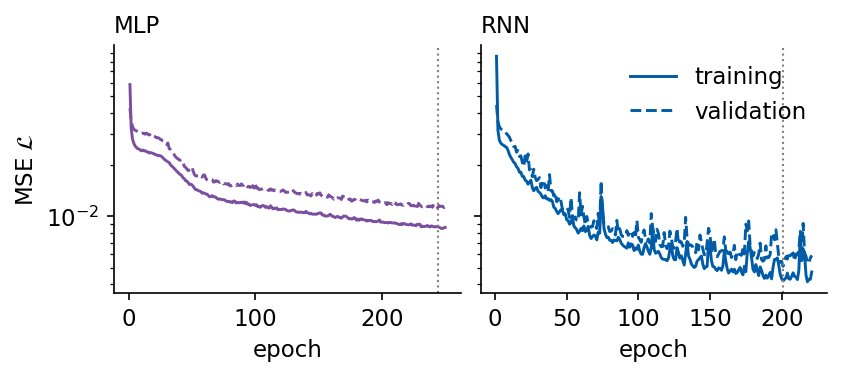

In [19]:
rnn_runs = {}                # rnn_runs[(L, n_h, seed)] = model, history and test scores

def train_rnn(L=L_WIN, n_h=N_H, seed=0, keep_model=False):
    key = (L, n_h, seed)
    if key not in rnn_runs:
        d_ = data_sf if L == L_WIN else net_data(s_sf, L)
        m, h = fit_network(make_rnn(seed, n_h), d_[:4], seed=seed)
        rnn_runs[key] = dict(model=m if keep_model else None, hist=h, n_params=n_params(m),
                             pred=predict(m, d_[4]), **score(predict(m, d_[4]), Y_TEST))
    return rnn_runs[key]

main = train_rnn(keep_model=True)
rnn_sf, h_rnn = main["model"], main["hist"]
res_sf["RNN"] = main
print(f"RNN n_h = {N_H}: {h_rnn['epochs_run']} epochs (best {h_rnn['best_epoch']}), {h_rnn['time']:.1f} s,"
      f" best validation loss {h_rnn['best_val']:.2e}, test C_tot = {main['Ctot']:.1f}")
print(f"gradient norm per update: median {np.median(h_rnn['gnorm']):.3f}, max {h_rnn['gnorm'].max():.3f},"
      f" fraction above the threshold {np.mean(h_rnn['gnorm'] > CLIP):.3f}")
h_mlp = mlp_runs[0]["hist"]
nums["training"] = dict(epochs=h_rnn["epochs_run"], best_epoch=h_rnn["best_epoch"], time_s=h_rnn["time"],
                        best_val=h_rnn["best_val"], train_at_best=float(h_rnn["train"][h_rnn["best_epoch"] - 1]),
                        gnorm_median=float(np.median(h_rnn["gnorm"])), gnorm_max=float(h_rnn["gnorm"].max()),
                        clipped_frac=float(np.mean(h_rnn["gnorm"] > CLIP)),
                        mlp_best_val=h_mlp["best_val"], mlp_epochs=h_mlp["epochs_run"], mlp_best_epoch=h_mlp["best_epoch"])

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.4), sharey=True, layout="constrained")
    for ax, (lab, h) in zip(axs, (("MLP", h_mlp), ("RNN", h_rnn))):
        ep = np.arange(1, h["epochs_run"] + 1)
        ax.semilogy(ep, h["train"], color=STYLE[lab]["color"], label="training")
        ax.semilogy(ep, h["val"], color=STYLE[lab]["color"], ls="--", label="validation")
        ax.axvline(h["best_epoch"], color="0.5", ls=":", lw=1.0)
        ax.set_title(lab, loc="left"); ax.set_xlabel("epoch")
    axs[0].set_ylabel(r"MSE $\mathcal{L}$"); axs[1].legend(loc="upper right")
    save(fig, "fig_lab038_training"); plt.show()

The figure shows the training loss, averaged over the minibatches of each epoch while the weights change, and the validation loss computed after each epoch, with the dotted line at the epoch of the lowest validation loss. Early stopping ended the RNN run after 221 epochs, with the lowest validation loss $5.10\times10^{-3}$ at epoch 201. The MLP ran all 250 epochs and reached $1.12\times10^{-2}$, more than twice the loss of the RNN, which has 2738 parameters against 7410. The validation loss of the RNN stays close to its training loss over the whole run, $4.19\times10^{-3}$ at the best epoch, so the network with 2738 parameters overfits the 2387 overlapping training windows at most weakly. The short spikes of both curves last one or two epochs, and keeping the best parameters makes the result insensitive to them. The gradient norm before clipping had the median 0.105 and a maximum of 0.729 over all updates, so the clipping threshold $\theta=1$ was never reached. For a network that starts from an orthogonal $W_h$ and reads inputs in $[0,1]$, clipping is a safeguard that this run did not need.

### Gradient clipping

To see clipping at work we need large gradients, and Section 4 tells us where to find them. We initialise the recurrent matrix in the expanding regime, $W_h=2\,O$ with a random orthogonal $O$, so that all its singular values equal 2. Such networks are trained with seeds 0, 1 and 2, once with clipping at $\theta=1$ and once without, with all other settings unchanged. The figure shows the gradient norm $\|\mathbf G\|$ before clipping at every update and the validation loss after every epoch, for seed 0 and for the network of the previous subsection.

rho = 2.0, seed 0, clipping on :  87 epochs, best validation loss 2.22e-02, median ||G||     0.146, max ||G||     1317.6, updates above 1: 0.087, test C_tot = 22.6


rho = 2.0, seed 0, clipping off:  58 epochs, best validation loss 3.36e-02, median ||G||     5.900, max ||G||     1834.0, updates above 1: 0.992, test C_tot = 10.1


rho = 2.0, seed 1, clipping on : 250 epochs, best validation loss 8.61e-03, median ||G||     0.095, max ||G||     1895.5, updates above 1: 0.042, test C_tot = 37.8


rho = 2.0, seed 1, clipping off:  52 epochs, best validation loss 3.60e-02, median ||G||    25.108, max ||G||     1932.5, updates above 1: 1.000, test C_tot = 8.3


rho = 2.0, seed 2, clipping on :  52 epochs, best validation loss 1.98e-02, median ||G||     0.179, max ||G||     1570.7, updates above 1: 0.155, test C_tot = 25.5


rho = 2.0, seed 2, clipping off:  52 epochs, best validation loss 3.72e-02, median ||G||    26.683, max ||G||     1911.2, updates above 1: 1.000, test C_tot = 6.6


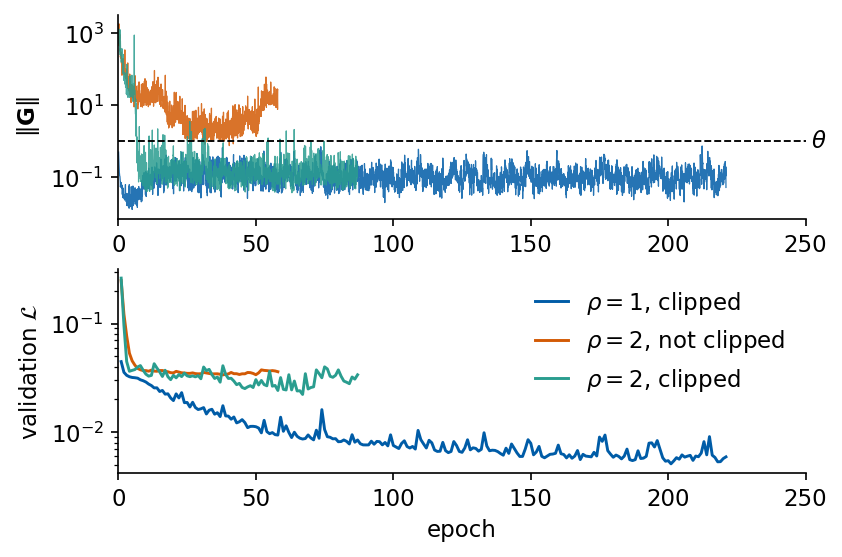

In [20]:
RHO_X = 2.0
clip_runs = {}
for seed in SEEDS:
    for clip in (CLIP, None):
        m, h = fit_network(make_rnn(seed, rho=RHO_X), data_sf[:4], seed=seed, clip=clip)
        clip_runs[(seed, clip)] = dict(hist=h, **score(predict(m, data_sf[4]), Y_TEST))
        print(f"rho = {RHO_X}, seed {seed}, clipping {'on ' if clip else 'off'}: {h['epochs_run']:3d} epochs,"
              f" best validation loss {h['best_val']:.2e}, median ||G|| {np.median(h['gnorm']):9.3f},"
              f" max ||G|| {h['gnorm'].max():10.1f}, updates above 1: {np.mean(h['gnorm'] > 1):.3f}, test C_tot = {clip_runs[(seed, clip)]['Ctot']:.1f}")
nums["clipping"] = {("on" if c else "off"): dict(Ctot=[clip_runs[(s_, c)]["Ctot"] for s_ in SEEDS],
                                                  best_val=[clip_runs[(s_, c)]["hist"]["best_val"] for s_ in SEEDS],
                                                  gnorm_median=[float(np.median(clip_runs[(s_, c)]["hist"]["gnorm"])) for s_ in SEEDS],
                                                  frac_above=[float(np.mean(clip_runs[(s_, c)]["hist"]["gnorm"] > 1)) for s_ in SEEDS])
                    for c in (CLIP, None)}

CURVES = ((r"$\rho=1$, clipped", h_rnn, UJBlue, "-"),
          (rf"$\rho={RHO_X:.0f}$, not clipped", clip_runs[(0, None)]["hist"], DSOrange, "-"),
          (rf"$\rho={RHO_X:.0f}$, clipped", clip_runs[(0, CLIP)]["hist"], GREEN, "-"))
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 1, figsize=(5.5, 3.6), layout="constrained")
    for lab, h, c, ls in CURVES:
        steps = np.arange(1, len(h["gnorm"]) + 1) / h["steps_per_epoch"]
        axs[0].semilogy(steps, h["gnorm"], color=c, lw=0.6, alpha=0.85, label=lab)
        axs[1].semilogy(np.arange(1, h["epochs_run"] + 1), h["val"], color=c, ls=ls, label=lab)
    axs[0].axhline(CLIP, color="k", ls="--", lw=0.9); axs[0].text(252, CLIP, r"$\theta$", va="center", ha="left")
    axs[0].set_ylabel(r"$\|\mathbf{G}\|$"); axs[1].set_ylabel(r"validation $\mathcal{L}$")
    axs[1].set_xlabel("epoch")
    for ax in axs: ax.set_xlim(0, MAX_EPOCHS)
    axs[1].legend(loc="upper right", ncol=1, handlelength=1.4)
    save(fig, "fig_lab038_clipping"); plt.show()

At initialisation with $\rho=2$ the gradient norm is of order $10^3$, with maxima between 1318 and 1933 over the six runs. Without clipping the large gradients persist. Adam bounds the size of every step, and still the median gradient norm over the run is 5.9, 25.1 and 26.7 for the three seeds, between 99.2% and 100% of the updates exceed 1, the validation loss stalls between $3.4\times10^{-2}$ and $3.7\times10^{-2}$, and early stopping ends the runs after 52 to 58 epochs with test $C_{\rm tot}$ of 10.1, 8.3 and 6.6. With clipping the gradient norm of seed 0 drops below the threshold within about ten epochs, and the medians over the runs are 0.15, 0.10 and 0.18. The best validation losses become $2.2\times10^{-2}$, $0.86\times10^{-2}$ and $2.0\times10^{-2}$ and the test $C_{\rm tot}$ 22.6, 37.8 and 25.5. Clipping thus turns three failed runs into working ones, and with seed 1 the network comes within four units of the orthogonal start with the same seed (41.6). The other two clipped runs ended after 87 and 52 epochs, when the validation loss had not improved for 20 epochs, at a clearly higher loss than the run started with $\rho=1$. In this experiment clipping repairs a bad initialisation only in part, and the orthogonal initialisation avoids the problem from the start.

### Jacobians of the trained network

After training, the recurrent matrix is no longer orthogonal. We repeat the Jacobian measurement of Section 4 for the trained network and compare it with the same network at initialisation (seed 0, $\rho=1$). A second quantity tells which inputs the trained forecaster uses. The input sensitivity
$$S(m)=\Big\langle\Big\|\frac{\partial\hat{\mathbf y}_k}{\partial s_{k-m}}\Big\|_2\Big\rangle_k ,\qquad m=0,\dots,L-1,$$
is the norm over the 50 outputs of the derivative of the forecast with respect to the input $m$ steps before the origin, averaged over the test origins. We compute it with `jax.jacrev` for the RNN and the MLP, which read the same window.

trained W_h: spectral radius 1.399, largest singular value 2.329, smallest 0.080


trained network: mean log10 ||J(m)||_2 at m = 1, 10, 30, 63: 0.27 0.57 0.14 -0.48 | rate (m >= 10) = -0.048


RNN: S(0) = 1.907, S(8) = 3.356, S(16) = 3.038, S(32) = 1.341, S(63) = 0.189; maximum S = 3.499 at m = 10, S(63) / max S = 0.054
MLP: S(0) = 3.739, S(8) = 1.183, S(16) = 1.029, S(32) = 0.921, S(63) = 0.669; maximum S = 3.739 at m = 0, S(63) / max S = 0.179


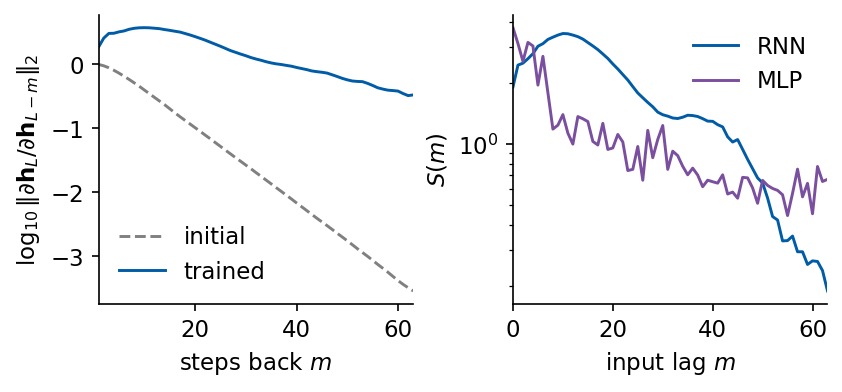

In [21]:
Kh_tr = np.asarray(rnn_sf.cell.Wh.kernel[...], np.float64)
sv = np.linalg.svd(Kh_tr, compute_uv=False)
spec_rad = np.max(np.abs(np.linalg.eigvals(Kh_tr)))
print(f"trained W_h: spectral radius {spec_rad:.3f}, largest singular value {sv[0]:.3f}, smallest {sv[-1]:.3f}")
jac_trained, jac_init = jac_profile(rnn_sf, V_j).mean(1), jac_profile(make_rnn(0), V_j).mean(1)
rate_tr = np.polyfit(mm[mm >= 10], jac_trained[mm >= 10] * np.log(10), 1)[0]
print(f"trained network: mean log10 ||J(m)||_2 at m = 1, 10, 30, 63: {jac_trained[0]:.2f} {jac_trained[9]:.2f}"
      f" {jac_trained[29]:.2f} {jac_trained[-1]:.2f} | rate (m >= 10) = {rate_tr:+.3f}")

def input_sensitivity(model, V):
    # S(m) = mean over windows of || d y_hat / d s_{k-m} ||_2 ; m = 0 is the newest value s_k
    jac = jax.vmap(jax.jacrev(lambda v: model(v[None])[0]))(V)        # (B, 50, L, 1)
    S = jnp.linalg.norm(jac[..., 0], axis=1).mean(0)                    # (L,), position L-1 is s_k
    return np.asarray(S[::-1])
S_rnn, S_mlp = input_sensitivity(rnn_sf, data_sf[4]), input_sensitivity(mlp_runs[0]["model"], data_sf[4])
m_in = np.arange(L_WIN)
for lab, S in (("RNN", S_rnn), ("MLP", S_mlp)):
    print(f"{lab}: S(0) = {S[0]:.3f}, S(8) = {S[8]:.3f}, S(16) = {S[16]:.3f}, S(32) = {S[32]:.3f}, S(63) = {S[63]:.3f};"
          f" maximum S = {S.max():.3f} at m = {int(np.argmax(S))}, S(63) / max S = {S[63] / S.max():.3f}")
nums["trained_jac"] = dict(spectral_radius=float(spec_rad), sv_max=float(sv[0]), sv_min=float(sv[-1]), rate=float(rate_tr),
                           log10_m10=float(jac_trained[9]), log10_m30=float(jac_trained[29]), log10_m63=float(jac_trained[-1]),
                           init_log10_m30=float(jac_init[29]))
nums["input_sensitivity"] = {lab: dict(S0=float(S[0]), S16=float(S[16]), S32=float(S[32]), S63=float(S[63]),
                                      m_peak=int(np.argmax(S)), ratio_63=float(S[63] / S.max()))
                             for lab, S in (("RNN", S_rnn), ("MLP", S_mlp))}

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.5), layout="constrained")
    ax = axs[0]
    ax.plot(mm, jac_init, color="0.5", ls="--", label="initial")
    ax.plot(mm, jac_trained, color=UJBlue, label="trained")
    ax.set_xlabel("steps back $m$"); ax.set_ylabel(r"$\log_{10}\|\partial\mathbf{h}_L/\partial\mathbf{h}_{L-m}\|_2$")
    ax.set_xlim(1, L_WIN - 1); ax.legend(loc="lower left")
    ax = axs[1]
    ax.semilogy(m_in, S_rnn, color=UJBlue, label="RNN")
    ax.semilogy(m_in, S_mlp, color=STYLE["MLP"]["color"], label="MLP")
    ax.set_xlabel("input lag $m$"); ax.set_ylabel("$S(m)$"); ax.set_xlim(0, L_WIN - 1); ax.legend(loc="upper right")
    save(fig, "fig_lab038_jacobian_trained"); plt.show()

Training has moved the recurrent matrix far from the orthogonal start. Its spectral radius is 1.40, its largest singular value 2.33 and its smallest 0.080. The Jacobian product of the trained network first grows, to $10^{0.57}$ at $m=10$, and then decays slowly, at the rate $-0.048$ per step, to $10^{-0.48}$ at $m=63$. The same network at initialisation had decayed to $10^{-1.57}$ already at $m=30$. Training has brought the hidden dynamics close to the boundary between contraction and expansion, where a perturbation of the state at the beginning of the window still reaches the last state.

The input sensitivity shows how the forecaster uses this. For the RNN $S(m)$ rises from 1.91 at the newest value to its maximum 3.50 at $m=10$, a little more than one pulsation period back, and falls to 0.19 at the oldest input, 5% of the maximum. The forecasts of the RNN thus depend most on the last two pulsations and only weakly on the beginning of the window. The MLP depends most on the newest value, $S(0)=3.74$, and keeps a tail of about 0.7 up to the oldest input, 18% of its maximum, with large changes between neighbouring lags. The smooth curve of the RNN is consistent with the same weights being applied at every step, while the MLP has an independent weight for every position of the window.

### Forecaster from flax nnx.SimpleCell

The forecaster can also be assembled from library pieces alone. `nnx.SimpleCell` is the Elman cell, `nnx.RNN` runs a cell over the time axis of a batch-major input of shape $(B,L,1)$ and with `return_carry=True` returns the last state next to the sequence of states, and an `nnx.Linear` reads out the last state. The library cell draws its input matrix from the LeCun normal distribution and its recurrent matrix as a random orthogonal matrix, the same distributions as our cell, but from different random numbers. We first copy the weights of our trained network into the library forecaster and compare outputs and gradients, and then train the library forecaster from its own initialisation with the same `fit_network`, the same Adam optimiser from `optax`, clipping and early stopping, for seeds 0, 1 and 2.

In [22]:
class SimpleCellForecaster(nnx.Module):
    # nnx.SimpleCell run by nnx.RNN from h_0 = 0, linear readout of the last state
    def __init__(self, n_h, n_out, *, rngs):
        self.n_h = n_h
        self.rnn = nnx.RNN(nnx.SimpleCell(1, n_h, rngs=rngs), return_carry=True)
        self.head = nnx.Linear(n_h, n_out, rngs=rngs)
    def __call__(self, V):
        h_last, _ = self.rnn(V, initial_carry=jnp.zeros((V.shape[0], self.n_h), V.dtype))
        return self.head(h_last)

lib_fc = SimpleCellForecaster(N_H, TAU_MAX, rngs=nnx.Rngs(0))
assert n_params(lib_fc) == n_params(rnn_sf)
cell = lib_fc.rnn.cell                                       # copy the weights of our trained RNN
cell.dense_i.kernel[...] = rnn_sf.cell.Wx.kernel[...]; cell.dense_i.bias[...] = rnn_sf.cell.Wx.bias[...]
cell.dense_h.kernel[...] = rnn_sf.cell.Wh.kernel[...]
lib_fc.head.kernel[...] = rnn_sf.head.kernel[...]; lib_fc.head.bias[...] = rnn_sf.head.bias[...]
print("trained weights copied: max |y_ours - y_SimpleCell| on the test windows =",
      float(jnp.abs(rnn_sf(data_sf[4]) - lib_fc(data_sf[4])).max()))
loss_p = lambda p, g, r: jnp.mean((nnx.merge(g, p, r)(V_b) - Y_b) ** 2)      # loss as a function of the parameters
g1, p1, r1 = nnx.split(rnn_sf, nnx.Param, ...); g2, p2, r2 = nnx.split(lib_fc, nnx.Param, ...)
G1 = jax.grad(loss_p)(p1, g1, r1); G2 = jax.grad(loss_p)(p2, g2, r2)
print("gradient of the recurrent kernel: max |ours - SimpleCell| =",
      float(jnp.abs(G1["cell"]["Wh"]["kernel"][...] - G2["rnn"]["cell"]["dense_h"]["kernel"][...]).max()),
      "| max entry", float(jnp.abs(G1["cell"]["Wh"]["kernel"][...]).max()))

lib_runs = {}
for seed in SEEDS:
    m, h = fit_network(SimpleCellForecaster(N_H, TAU_MAX, rngs=nnx.Rngs(seed)), data_sf[:4], seed=seed)
    lib_runs[seed] = dict(model=m, hist=h, pred=predict(m, data_sf[4]), **score(predict(m, data_sf[4]), Y_TEST))
    print(f"nnx.SimpleCell forecaster, seed {seed}: {h['epochs_run']} epochs (best {h['best_epoch']}),"
          f" best validation loss {h['best_val']:.2e}, test C_tot = {lib_runs[seed]['Ctot']:.1f}"
          f" | our RNN, seed {seed}: C_tot = {train_rnn(seed=seed)['Ctot']:.1f}")
res_sf["SimpleCell"] = lib_runs[0]

trained weights copied: max |y_ours - y_SimpleCell| on the test windows = 0.0


gradient of the recurrent kernel: max |ours - SimpleCell| = 0.0 | max entry 0.027298517525196075


nnx.SimpleCell forecaster, seed 0: 205 epochs (best 185), best validation loss 5.70e-03, test C_tot = 42.1 | our RNN, seed 0: C_tot = 42.5


nnx.SimpleCell forecaster, seed 1: 250 epochs (best 245), best validation loss 4.97e-03, test C_tot = 43.3 | our RNN, seed 1: C_tot = 41.6


nnx.SimpleCell forecaster, seed 2: 205 epochs (best 185), best validation loss 5.07e-03, test C_tot = 42.5 | our RNN, seed 2: C_tot = 42.2


With the weights of our trained network copied into the library forecaster, the outputs on all test windows and the gradient of the loss with respect to the recurrent kernel agree exactly, so `nnx.SimpleCell` inside `nnx.RNN` computes the same function and the same derivatives as our implementation. Trained from its own initialisation, the library forecaster reaches $C_{\rm tot}=42.1$, 43.3 and 42.5 for the seeds 0, 1 and 2, against 42.5, 41.6 and 42.2 for our RNN. The means, 42.7 and 42.1, differ by less than the spread over seeds of either model, so the two implementations train equally well. Individual runs differ because the random initial weights differ.

<hr/>
## 6. Forecasts

The capacity curves of all models on the test origins summarise the forecasts lead by lead. For the MLP and our RNN the line is seed 0 and the shaded band spans the three seeds, and the dashed light-blue line is the forecaster built from `nnx.SimpleCell` (seed 0).

RNN: C_tot for seeds 0, 1, 2 = 42.5, 41.6, 42.2 (mean 42.1)
MLP: C_tot for seeds 0, 1, 2 = 35.3, 35.6, 36.0 (mean 35.6)
SimpleCell: C_tot for seeds 0, 1, 2 = 42.1, 43.3, 42.5 (mean 42.7)


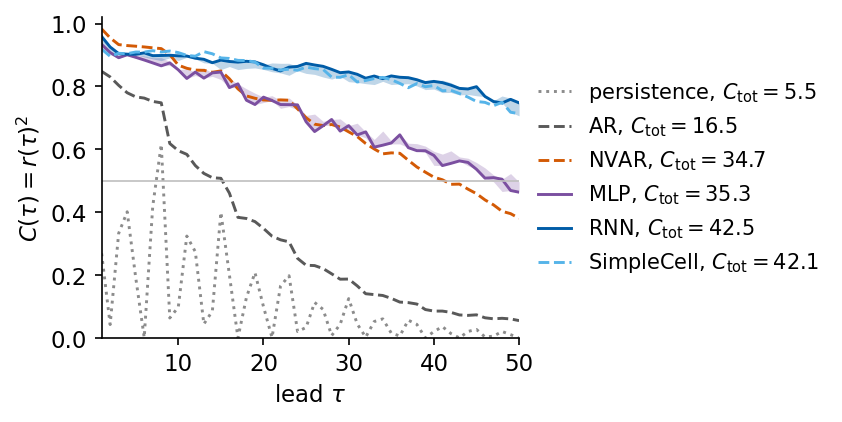

model         C_tot  tau_1/2    C(1)    C(2)    C(5)   C(10)   C(25)   C(50)
persistence     5.5        1   0.269   0.043   0.193   0.098   0.034   0.000
AR             16.5       16   0.848   0.830   0.767   0.596   0.232   0.056
NVAR           34.7       42   0.983   0.954   0.928   0.868   0.701   0.381
MLP            35.3       49   0.934   0.908   0.893   0.853   0.688   0.464
RNN            42.5      >50   0.959   0.925   0.902   0.897   0.873   0.748
SimpleCell     42.1      >50   0.919   0.896   0.909   0.908   0.862   0.713
RNN above NVAR at every lead from tau = 10 on; RNN above MLP at 50 of 50 leads


In [23]:
for seed in SEEDS[1:]:
    train_rnn(seed=seed)
seed_C = {"RNN": np.array([rnn_runs[(L_WIN, N_H, s_)]["C"] for s_ in SEEDS]),
          "MLP": np.array([mlp_runs[s_]["C"] for s_ in SEEDS]),
          "SimpleCell": np.array([lib_runs[s_]["C"] for s_ in SEEDS])}
seed_Ctot = {k: v.sum(1) for k, v in seed_C.items()}
for k, v in seed_Ctot.items():
    print(f"{k}: C_tot for seeds 0, 1, 2 = " + ", ".join(f"{x:.1f}" for x in v) + f" (mean {v.mean():.1f})")
nums["seeds_Ctot"] = {k: v.tolist() for k, v in seed_Ctot.items()}

ALL = ("persistence", "AR", "NVAR", "MLP", "RNN", "SimpleCell")
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.7), layout="constrained")
    for m in ALL:
        if m in ("MLP", "RNN"):
            ax.fill_between(TAUS, seed_C[m].min(0), seed_C[m].max(0), color=STYLE[m]["color"], alpha=0.25, lw=0)
        ax.plot(TAUS, res_sf[m]["C"], label=rf"{m}, $C_{{\rm tot}}={res_sf[m]['Ctot']:.1f}$", **STYLE[m])
    ax.axhline(0.5, color="0.75", lw=0.8)
    ax.set_xlabel(r"lead $\tau$"); ax.set_ylabel(r"$C(\tau)=r(\tau)^2$"); ax.set_xlim(1, TAU_MAX); ax.set_ylim(0, 1.02)
    ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5), handlelength=1.6, fontsize=10)
    save(fig, "fig_lab038_capacity"); plt.show()

print(f"{'model':12s}{'C_tot':>7s}{'tau_1/2':>9s}" + "".join(f"{'C(' + str(t) + ')':>8s}" for t in (1, 2, 5, 10, 25, 50)))
for m in ALL:
    print(f"{m:12s}{res_sf[m]['Ctot']:7.1f}{str(res_sf[m]['tau_half'] or '>50'):>9s}" + "".join(f"{res_sf[m]['C'][t - 1]:8.3f}" for t in (1, 2, 5, 10, 25, 50)))
above = res_sf["RNN"]["C"] > res_sf["NVAR"]["C"]
first_all = int(np.argmax([above[j:].all() for j in range(TAU_MAX)])) + 1
print(f"RNN above NVAR at every lead from tau = {first_all} on; RNN above MLP at {int(np.sum(res_sf['RNN']['C'] > res_sf['MLP']['C']))} of 50 leads")
nums["rnn_above_nvar_from"] = first_all

The RNN has the largest capacity at every lead from $\tau=10$ on, and its $C(\tau)$ stays above 0.5 up to the last lead, with $C(50)=0.748$, so $\tau_{1/2}>50$. At the shortest leads NVAR is better, $C(1)=0.983$ against 0.959 and $C(5)=0.928$ against 0.902. NVAR then loses capacity faster and crosses 0.5 at $\tau_{1/2}=42$. The MLP lies below the RNN at all 50 leads and close to NVAR, with $\tau_{1/2}=49$. The forecaster from `nnx.SimpleCell` (seed 0, $C_{\rm tot}=42.1$) follows our RNN within the seed band. Persistence oscillates with the pulsation period, since the value one period back resembles the present, and AR falls below 0.5 at $\tau=16$. The seed band of the RNN is narrow, $C_{\rm tot}=42.5$, 41.6 and 42.2 with the mean 42.1, and the gap to the MLP, whose mean is 35.6, is several times the spread over seeds. The MLP and the RNN read the same 64 values, so at these model sizes the gain of about 6.5 units comes from the way the window is processed, a recurrence with shared weights against a single layer on the whole window.

### Forecasts at several leads

The numbers become concrete in the forecasts themselves. The upper panels show the target $s_{k+\tau}$ (black) and the RNN forecast $\hat s_{k+\tau}$ (dashed) over the first 100 test origins for the leads $\tau=1,2,5,10$. The lower panels show the forecast against the target over all test origins, with the capacity $C(\tau)$ in the title.

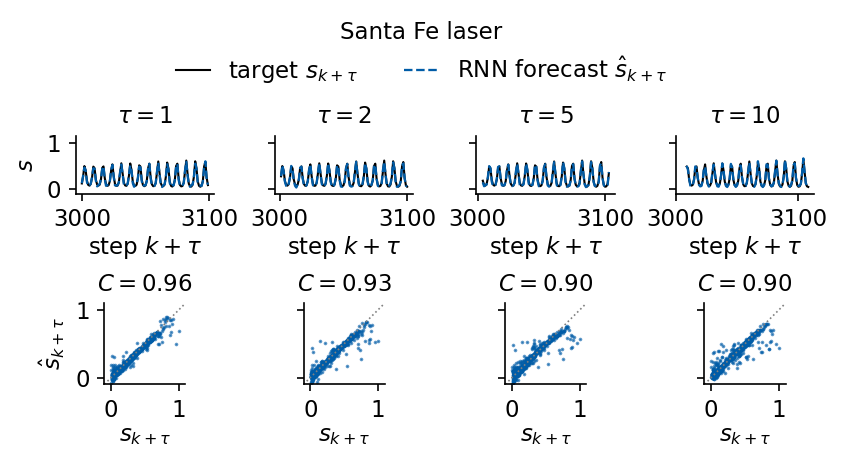

RNN C(tau) at tau = 1, 2, 5, 10: [0.959 0.925 0.902 0.897] | NVAR: [0.983 0.954 0.928 0.868]
tau = 10: 28 of 951 forecasts with |error| > 0.2; their target times k + 10 lie in [3204, 3956] | within 40 steps of a collapse: 6


In [24]:
TAU_SHOW, K_SHOW = (1, 2, 5, 10), 100

def leads_figure(name, fname):
    # upper row: target and RNN forecast on the first 100 test origins; lower row: forecast against target, C in the title
    P_rnn, Yt = res[name]["RNN"]["pred"], Y_T[name]
    fig, axs = plt.subplots(2, 4, figsize=(5.5, 3.0), layout="constrained", gridspec_kw={"height_ratios": [1.0, 1.4]})
    for c_, t in enumerate(TAU_SHOW):
        a_t, a_s = axs[0, c_], axs[1, c_]
        y_t, y_p = Yt[:, t - 1], P_rnn[:, t - 1]
        kk = K_TEST[:K_SHOW] + t
        a_t.plot(kk, y_t[:K_SHOW], color="k", lw=1.0, label=r"target $s_{k+\tau}$")
        a_t.plot(kk, y_p[:K_SHOW], "--", color=UJBlue, lw=1.1, label=r"RNN forecast $\hat s_{k+\tau}$")
        a_t.set_title(rf"$\tau={t}$"); a_t.set_ylim(-0.1, 1.15); a_t.set_yticks([0, 1])
        a_t.set_xticks([3000, 3100]); a_t.set_xlabel(r"step $k+\tau$", labelpad=1)
        a_s.plot(y_t, y_p, ".", ms=1.5, color=UJBlue, alpha=0.6)
        a_s.plot([-0.1, 1.1], [-0.1, 1.1], color="0.5", lw=0.8, ls=":")
        a_s.set_xlim(-0.1, 1.1); a_s.set_ylim(-0.1, 1.1); a_s.set_aspect("equal")
        a_s.set_xticks([0, 1]); a_s.set_yticks([0, 1]); a_s.set_xlabel(r"$s_{k+\tau}$", labelpad=1)
        a_s.set_title(f"$C={res[name]['RNN']['C'][t - 1]:.2f}$")
        if c_ > 0:
            a_t.set_yticklabels([]); a_s.set_yticklabels([])
    axs[0, 0].set_ylabel("$s$"); axs[1, 0].set_ylabel(r"$\hat s_{k+\tau}$")
    fig.legend(*axs[0, 0].get_legend_handles_labels(), loc="outside upper center", ncol=2, handlelength=1.5,
               title=LABEL[name], title_fontsize=11)
    save(fig, fname); plt.show()

with mpl.rc_context(SLIDE_RC):
    leads_figure("SantaFe", "fig_lab038_leads")
print("RNN C(tau) at tau = 1, 2, 5, 10:", np.round(res_sf["RNN"]["C"][[0, 1, 4, 9]], 3),
      "| NVAR:", np.round(res_sf["NVAR"]["C"][[0, 1, 4, 9]], 3))
err10 = res_sf["RNN"]["pred"][:, 9] - Y_TEST[:, 9]
k_bad = K_TEST[np.abs(err10) > 0.2] + 10                       # target times of the large errors at tau = 10
print(f"tau = 10: {len(k_bad)} of {len(K_TEST)} forecasts with |error| > 0.2; their target times k + 10 lie in",
      f"[{k_bad.min()}, {k_bad.max()}]" if len(k_bad) else "-",
      "| within 40 steps of a collapse:", int(np.sum([min(abs(k - c) for c in collapse) <= 40 for k in k_bad])))
nums["outliers_tau10"] = dict(n=int(len(k_bad)), k_min=int(k_bad.min()) if len(k_bad) else None, k_max=int(k_bad.max()) if len(k_bad) else None)

At $\tau=1$ the forecast follows the target closely, with $C=0.96$, and over the first 100 test origins the dashed curve is hard to tell from the black one at every lead shown. The scatter widens with the lead. Most points stay in a narrow band along the diagonal, and the capacity falls from 0.96 at $\tau=1$ to 0.90 at $\tau=10$. The largest pulses are underestimated, and a few points lie far from the diagonal. At $\tau=10$, 28 of the 951 forecasts miss by more than 0.2. Their target times are spread over the test block from $k+\tau=3204$ to 3956, and only 6 of them lie within 40 steps of the collapse at $k=3222$, so the large errors are not confined to the collapse.

### Hidden size and window length

The hidden size $n_h$ sets the capacity of the model, and the window length $L$ sets how much of the past it can see. We train the network for $n_h\in\{4,8,16,32,64,128\}$ at $L=64$ and for $L\in\{4,8,16,32,64\}$ at $n_h=32$, each with three seeds. All windows use the same fitting, validation and test origins, so only the length of the visible past changes. In practice the choice is made on the validation loss, and we show the test $C_{\rm tot}$ next to it to see how far the two agree.

sweeps trained in 325 s
n_h =   4:    274 parameters, test C_tot = 24.0, 24.2, 24.2 (mean 24.1), mean best validation loss 2.15e-02, 5 s per fit
n_h =   8:    530 parameters, test C_tot = 27.1, 28.2, 30.6 (mean 28.6), mean best validation loss 1.60e-02, 6 s per fit
n_h =  16:   1138 parameters, test C_tot = 40.0, 38.2, 39.3 (mean 39.2), mean best validation loss 8.18e-03, 10 s per fit
n_h =  32:   2738 parameters, test C_tot = 42.5, 41.6, 42.2 (mean 42.1), mean best validation loss 5.21e-03, 13 s per fit
n_h =  64:   7474 parameters, test C_tot = 40.9, 41.4, 41.0 (mean 41.1), mean best validation loss 4.51e-03, 20 s per fit
n_h = 128:  23090 parameters, test C_tot = 40.0, 41.3, 40.2 (mean 40.5), mean best validation loss 3.96e-03, 46 s per fit
L   =   4:   2738 parameters, test C_tot = 33.9, 33.1, 34.2 (mean 33.7), mean best validation loss 1.25e-02, 2 s per fit
L   =   8:   2738 parameters, test C_tot = 38.7, 39.4, 38.1 (mean 38.7), mean best validation loss 8.01e-03, 3 s per fit
L   

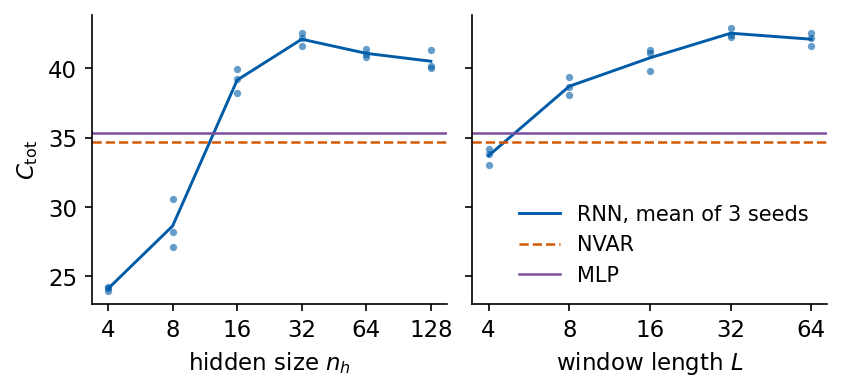

In [25]:
H_SIZES, L_SIZES = (4, 8, 16, 32, 64, 128), (4, 8, 16, 32, 64)
t0 = time.time()
for n_h in H_SIZES:
    for seed in SEEDS:
        train_rnn(n_h=n_h, seed=seed)
for L_ in L_SIZES:
    for seed in SEEDS:
        train_rnn(L=L_, seed=seed)
print(f"sweeps trained in {time.time() - t0:.0f} s")

def sweep_table(keys, name):
    rows = []
    for lab, ks in keys:
        runs = [rnn_runs[k] for k in ks]
        ct, vl = np.array([r["Ctot"] for r in runs]), np.array([r["hist"]["best_val"] for r in runs])
        tt = np.mean([r["hist"]["time"] for r in runs])
        rows.append(dict(value=lab, params=runs[0]["n_params"], Ctot=ct.tolist(), Ctot_mean=float(ct.mean()),
                         val_mean=float(vl.mean()), time_mean=float(tt)))
        print(f"{name} = {lab:3d}: {runs[0]['n_params']:6d} parameters, test C_tot = " + ", ".join(f"{x:.1f}" for x in ct)
              + f" (mean {ct.mean():.1f}), mean best validation loss {vl.mean():.2e}, {tt:.0f} s per fit")
    return rows
sweep_h = sweep_table([(n_h, [(L_WIN, n_h, s_) for s_ in SEEDS]) for n_h in H_SIZES], "n_h")
sweep_L = sweep_table([(L_, [(L_, N_H, s_) for s_ in SEEDS]) for L_ in L_SIZES], "L  ")
nums["sweep_hidden"], nums["sweep_window"] = sweep_h, sweep_L

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.5), sharey=True, layout="constrained")
    for ax, rows, xl in ((axs[0], sweep_h, "hidden size $n_h$"), (axs[1], sweep_L, "window length $L$")):
        x = np.array([r["value"] for r in rows])
        for j, r in enumerate(rows):
            ax.plot([x[j]] * 3, r["Ctot"], "o", ms=3.5, color=UJBlue, alpha=0.6, mec="none")
        ax.plot(x, [r["Ctot_mean"] for r in rows], color=UJBlue, label="RNN, mean of 3 seeds")
        for m in ("NVAR", "MLP"):
            ax.axhline(res_sf[m]["Ctot"], label=m, lw=1.2, **STYLE[m])
        ax.set_xscale("log", base=2); ax.set_xticks(x); ax.set_xticklabels([str(v) for v in x]); ax.minorticks_off()
        ax.set_xlabel(xl)
    axs[0].set_ylabel(r"$C_{\rm tot}$"); axs[1].legend(loc="lower right", fontsize=10)
    save(fig, "fig_lab038_sweeps"); plt.show()

The hidden size matters most at small sizes. With $n_h=4$ and 274 parameters the mean test $C_{\rm tot}$ is 24.1, with $n_h=8$ it is 28.6, and $n_h=16$ already exceeds NVAR and the MLP with 39.2. The best mean, 42.1, belongs to $n_h=32$, and the larger networks give 41.1 ($n_h=64$) and 40.5 ($n_h=128$). The mean validation loss, in contrast, keeps decreasing up to $n_h=128$, from $5.21\times10^{-3}$ at $n_h=32$ to $3.96\times10^{-3}$. A choice by validation loss would therefore pick the largest network, whose test $C_{\rm tot}$ is lower by 1.6 than at $n_h=32$, a difference somewhat larger than the spread over seeds. The validation block and the test block contain different collapses, and a few hundred samples are too short to rank the larger networks reliably.

The window length shows how much past the forecast needs. With $L=4$, half a pulsation period, the mean $C_{\rm tot}$ is 33.7, below NVAR with its 32 delays, and one period ($L=8$) raises it to 38.7. From $L=16$ on the gain flattens, with 40.8 at $L=16$, 42.5 at $L=32$ and 42.1 at $L=64$, and the validation losses of $L=32$ and $L=64$ differ by less than 4%. A window of a few pulsation periods holds most of the information the network uses, consistent with the input sensitivity above, and the cost of a fit grows with $L$ because BPTT runs through every step of the window.

### Forecasts of the Mackey–Glass signals

The same protocol is now applied to the three Mackey–Glass signals. We train our RNN and the forecaster from `nnx.SimpleCell` with $n_h=32$, $L=64$ and seed 0 on each of them, with no change of any setting, and collect the capacity curves of all models for the four signals.

MG15: RNN 250 epochs, C_tot = 50.0 | nnx.SimpleCell 209 epochs, C_tot = 49.9


MG25: RNN 164 epochs, C_tot = 49.4 | nnx.SimpleCell 250 epochs, C_tot = 49.5


MG35: RNN 239 epochs, C_tot = 49.7 | nnx.SimpleCell 206 epochs, C_tot = 49.6

model          SantaFe      MG15      MG25      MG35     (C_tot, maximum 50)
persistence        5.5      19.5      13.3      11.8
AR                16.5      49.8      33.1      38.0
NVAR              34.7      50.0      45.5      48.6
MLP               35.3      50.0      48.4      49.5
RNN               42.5      50.0      49.4      49.7
SimpleCell        42.1      49.9      49.5      49.6

model          SantaFe      MG15      MG25      MG35     (tau_1/2, '>50' if C stays above 0.5)
persistence          1         6         8        10
AR                  16       >50        42       >50
NVAR                42       >50       >50       >50
MLP                 49       >50       >50       >50
RNN                >50       >50       >50       >50
SimpleCell         >50       >50       >50       >50

model          SantaFe      MG15      MG25      MG35     (C(50))
persistence      0.000     0.368     0.059     

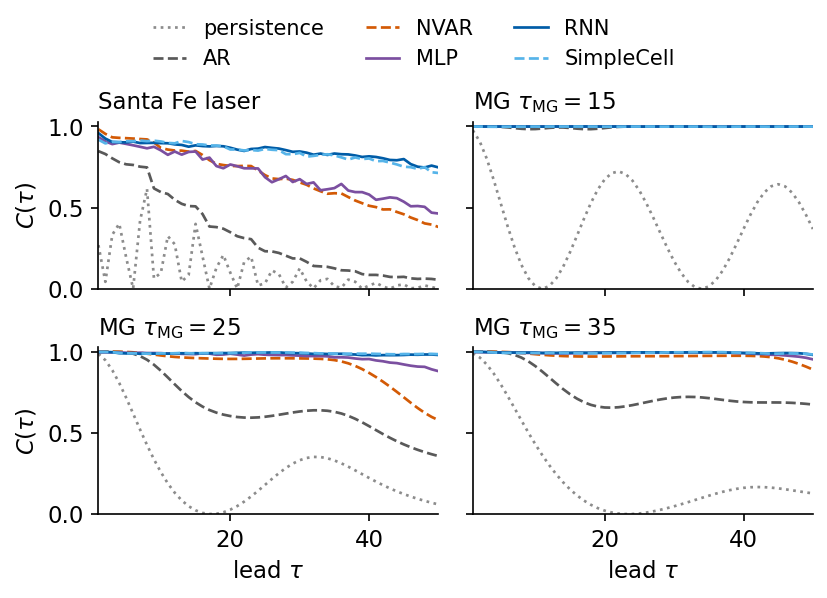

In [26]:
for name in SIGNALS[1:]:
    m, h = fit_network(make_rnn(0), data[name][:4], seed=0)
    res[name]["RNN"] = dict(pred=predict(m, data[name][4]), epochs=h["epochs_run"], **score(predict(m, data[name][4]), Y_T[name]))
    m, h2 = fit_network(SimpleCellForecaster(N_H, TAU_MAX, rngs=nnx.Rngs(0)), data[name][:4], seed=0)
    res[name]["SimpleCell"] = dict(pred=predict(m, data[name][4]), epochs=h2["epochs_run"], **score(predict(m, data[name][4]), Y_T[name]))
    print(f"{name}: RNN {h['epochs_run']} epochs, C_tot = {res[name]['RNN']['Ctot']:.1f} | nnx.SimpleCell {h2['epochs_run']} epochs,"
          f" C_tot = {res[name]['SimpleCell']['Ctot']:.1f}")

print(f"\n{'model':12s}" + "".join(f"{n:>10s}" for n in SIGNALS) + "     (C_tot, maximum 50)")
for m in ALL:
    print(f"{m:12s}" + "".join(f"{res[n][m]['Ctot']:10.1f}" for n in SIGNALS))
print(f"\n{'model':12s}" + "".join(f"{n:>10s}" for n in SIGNALS) + "     (tau_1/2, '>50' if C stays above 0.5)")
for m in ALL:
    print(f"{m:12s}" + "".join(f"{(res[n][m]['tau_half'] or '>50'):>10}" for n in SIGNALS))
print(f"\n{'model':12s}" + "".join(f"{n:>10s}" for n in SIGNALS) + "     (C(50))")
for m in ALL:
    print(f"{m:12s}" + "".join(f"{res[n][m]['C'][-1]:10.3f}" for n in SIGNALS))
nums["Ctot_all"] = {n: {m: res[n][m]["Ctot"] for m in ALL} for n in SIGNALS}
nums["tau_half_all"] = {n: {m: res[n][m]["tau_half"] for m in ALL} for n in SIGNALS}
nums["C_tau_all"] = {n: {m: {t: float(res[n][m]["C"][t - 1]) for t in (1, 2, 5, 10, 25, 50)} for m in ALL} for n in SIGNALS}
nums["ridge_choice"] = {n: {m: dict(p=res[n][m]["p"], beta=res[n][m]["beta"], n_feat=res[n][m]["n_feat"]) for m in ("AR", "NVAR")}
                        for n in SIGNALS}

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 2, figsize=(5.5, 3.9), sharex=True, sharey=True, layout="constrained")
    for ax, name in zip(axs.ravel(), SIGNALS):
        for m in ALL:
            ax.plot(TAUS, res[name][m]["C"], lw=1.3, label=m, **STYLE[m])
        ax.set_title(LABEL[name], loc="left"); ax.set_ylim(0, 1.03); ax.set_xlim(1, TAU_MAX)
    for ax in axs[1]: ax.set_xlabel(r"lead $\tau$")
    for ax in axs[:, 0]: ax.set_ylabel(r"$C(\tau)$")
    fig.legend(*axs[0, 0].get_legend_handles_labels(), loc="outside upper center", ncol=3, handlelength=1.6, fontsize=10)
    save(fig, "fig_lab038_capacity_signals"); plt.show()

On the Mackey–Glass signals all trained networks come close to the maximum. At $\tau_{\rm MG}=15$ every model except persistence reaches $C_{\rm tot}$ between 49.8 and 50.0. At $\tau_{\rm MG}=25$ our RNN reaches 49.4 and the forecaster from `nnx.SimpleCell` 49.5, with $C(50)=0.980$ and 0.985, against 48.4 for the MLP, 45.5 for NVAR and 33.1 for AR. At $\tau_{\rm MG}=35$ the RNN, the library RNN and the MLP give 49.7, 49.6 and 49.5, and NVAR 48.6. The differences between the networks on Mackey–Glass are below one unit of $C_{\rm tot}$, smaller than the seed spread measured on Santa Fe, and these runs use one seed only, so they do not rank the networks. The ranking that the data support is the one of the model classes. Linear AR loses capacity on the chaotic signals, the quadratic NVAR recovers most of it, and the networks recover nearly all of it. Unlike the laser, these signals change smoothly within the window, and a window of 64 values with a moderate nonlinear map suffices for forecasts with $C(\tau)$ close to 1 over all 50 leads.

The forecasts of the RNN at the leads $\tau=1,2,5,10$ are shown for each Mackey–Glass signal in the same layout as for the laser, the target $s_{k+\tau}$ and the forecast $\hat s_{k+\tau}$ over the first 100 test origins in the upper row and the forecast against the target over all test origins, with $C(\tau)$ in the title, in the lower row.

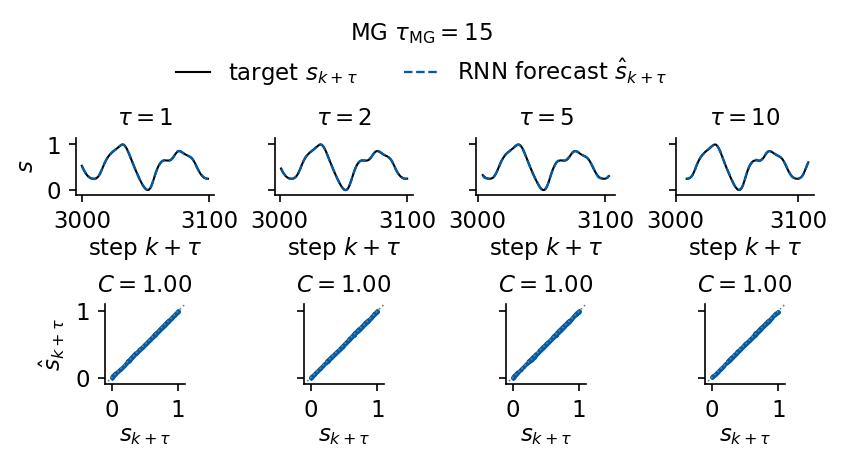

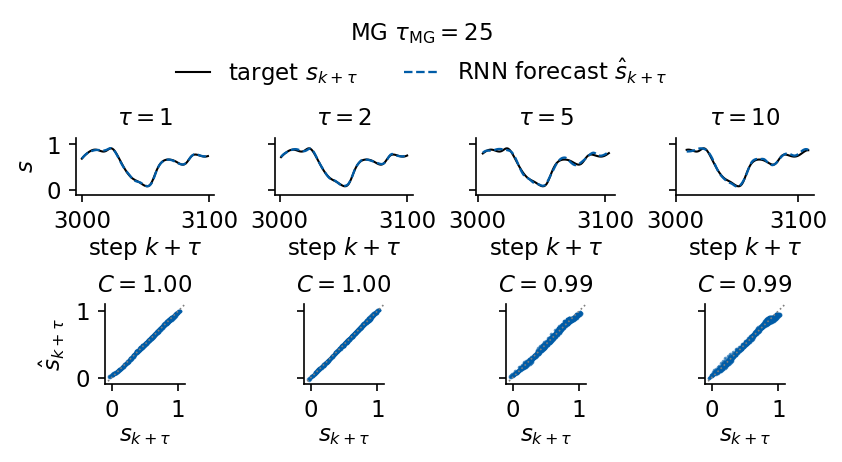

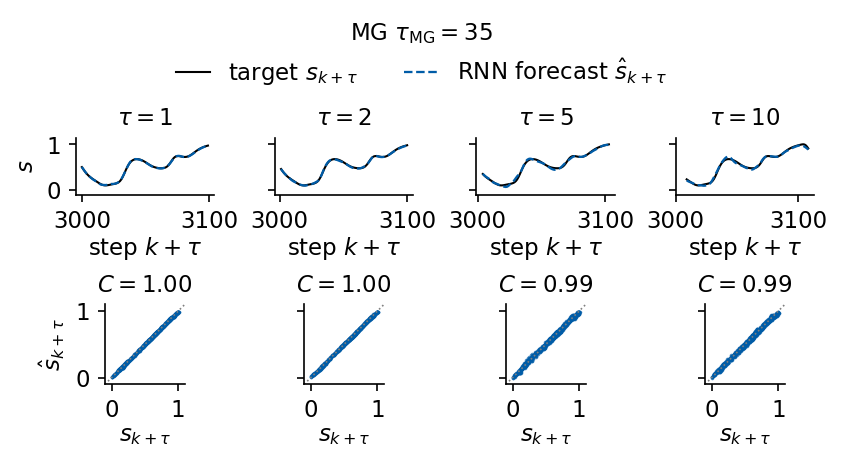

MG15: RNN C(tau) at tau = 1, 2, 5, 10: [0.9998 0.9997 0.9995 0.9996]
MG25: RNN C(tau) at tau = 1, 2, 5, 10: [0.9977 0.9985 0.9894 0.9892]
MG35: RNN C(tau) at tau = 1, 2, 5, 10: [0.9994 0.9992 0.9949 0.9945]


In [27]:
with mpl.rc_context(SLIDE_RC):
    for name in SIGNALS[1:]:
        leads_figure(name, f"fig_lab038_leads_{name}")
for name in SIGNALS[1:]:
    print(f"{name}: RNN C(tau) at tau = 1, 2, 5, 10:", np.round(res[name]["RNN"]["C"][[0, 1, 4, 9]], 4))

For the Mackey–Glass signals the forecasts at the four leads lie on the targets and the scatter plots are thin lines along the diagonal. The capacity of the RNN at $\tau=1,2,5,10$ is 0.9998, 0.9997, 0.9995 and 0.9996 for $\tau_{\rm MG}=15$, between 0.989 and 0.999 for $\tau_{\rm MG}=25$ and between 0.991 and 0.999 for $\tau_{\rm MG}=35$. In the chaotic regimes the scatter widens slightly at $\tau=5$ and $\tau=10$, and for $\tau_{\rm MG}=25$ the forecast underestimates the largest values.

The last figure of this notebook collects the forecasts of the RNN at the leads $\tau=1$, 5 and 10 on all four signals. Each row belongs to one signal and each column to one lead, and every panel shows the first 100 targets of the test block together with the forecast. The title of a panel gives the capacity $C(\tau)$ computed on the whole test block, so the four rows can be compared lead by lead.

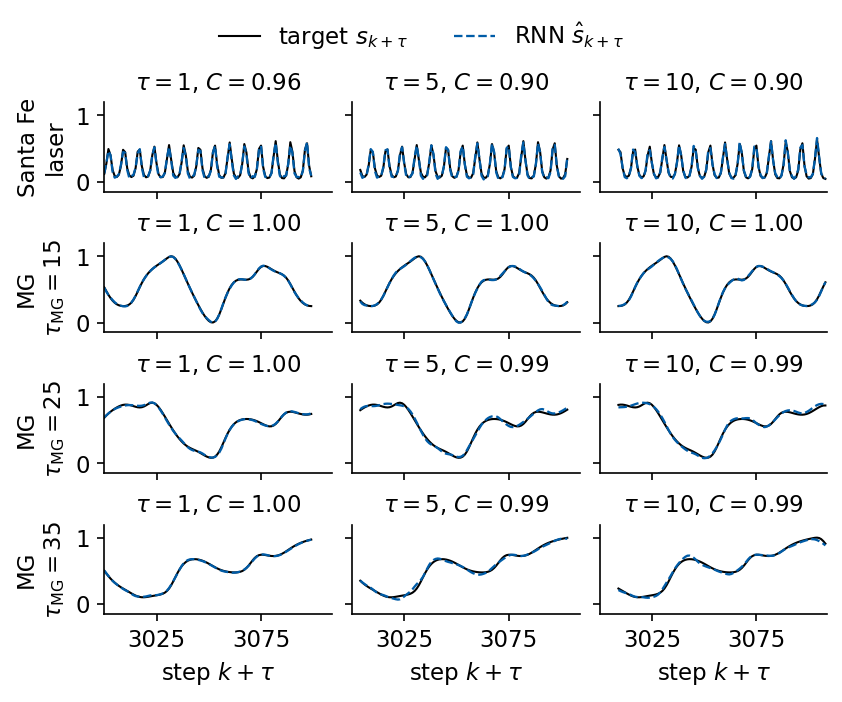

RNN C(tau) on the test block
signal        C(1)    C(5)   C(10)
SantaFe      0.959   0.902   0.897
MG15         1.000   0.999   1.000
MG25         0.998   0.989   0.989
MG35         0.999   0.995   0.995


In [28]:
TAU_ALL = (1, 5, 10)
COL_RNN = "#005CA7"          # model colour shared by the summary figures of the MLP, RNN, LSTM and GRU notebooks
SIG_ALL = ("SantaFe", "MG15", "MG25", "MG35")
YLAB = {n: LABEL[n].replace(" $", "\n$").replace(" laser", "\nlaser") for n in SIG_ALL}   # signal label on two lines
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(len(SIG_ALL), len(TAU_ALL), figsize=(5.5, 4.6), layout="constrained")
    for r_, name in enumerate(SIG_ALL):
        Yt_ = windows(sig[name], K_TEST)[1]
        P_ = res[name]["RNN"]["pred"]
        for c_, t in enumerate(TAU_ALL):
            ax = axs[r_, c_]
            kk = K_TEST[:K_SHOW] + t                      # steps k + tau of the first 100 test targets
            ax.plot(kk, Yt_[:K_SHOW, t - 1], color="k", lw=1.0, label=r"target $s_{k+\tau}$")
            ax.plot(kk, P_[:K_SHOW, t - 1], "--", color=COL_RNN, lw=1.1, label=r"RNN $\hat s_{k+\tau}$")
            ax.set_title(rf"$\tau={t}$, $C={res[name]['RNN']['C'][t - 1]:.2f}$")
            ax.set_ylim(-0.15, 1.2); ax.set_yticks([0, 1])
            ax.set_xlim(N_TRAIN, N_TRAIN + K_SHOW + max(TAU_ALL) - 1); ax.set_xticks([3025, 3075])
            if c_ == 0: ax.set_ylabel(YLAB[name])
            else: ax.set_yticklabels([])
            if r_ == len(SIG_ALL) - 1: ax.set_xlabel(r"step $k+\tau$")
            else: ax.set_xticklabels([])
    fig.legend(*axs[0, 0].get_legend_handles_labels(), loc="outside upper center", ncol=2, handlelength=1.8)
    save(fig, "fig_lab038_leads_all"); plt.show()

print(f"RNN C(tau) on the test block")
print(f"{'signal':10s}" + "".join(f"{'C(' + str(t) + ')':>8s}" for t in TAU_ALL))
for name in SIG_ALL:
    print(f"{name:10s}" + "".join(f"{res[name]['RNN']['C'][t - 1]:8.3f}" for t in TAU_ALL))


<hr/>
## Summary

We used the Elman recurrent network as a direct forecaster of 50 leads from a window of $L=64$ past values, fed from $\mathbf h_0=0$ and read out once from the last state, and scored it by the capacity $C(\tau)=r(\tau)^2$ and its sum $C_{\rm tot}$. Our RNN implementation in JAX agrees exactly with the flax `nnx.SimpleCell` in outputs and gradients, and the forecaster assembled from the library pieces trains to the same accuracy within the spread over seeds.

Training a recurrent network runs backpropagation through time, and every contribution of an earlier step to the gradient carries a product of step Jacobians $D_iW_h$. For untrained networks with all singular values of $W_h$ equal to $\rho$ this product decayed at the rate $-0.755$ per step for $\rho=0.5$ and $-0.146$ for $\rho=1$, and grew slowly, $+0.030$, for $\rho=1.5$, where the saturation of tanh limits the growth. A network started from $\rho=2$ produced gradient norms of order $10^3$. Without clipping all three such runs failed, with $C_{\rm tot}$ between 6.6 and 10.1, and clipping at norm 1 raised them to between 22.6 and 37.8. From the orthogonal start the gradient norm stayed below 0.73 and clipping was never active. Training moved the network close to the boundary between contracting and expanding hidden dynamics, with a slow decay of the Jacobian product at the rate $-0.048$ per step, and its forecasts depend most on the last two pulsations of the laser.

On the Santa Fe laser the RNN with 32 hidden units reaches $C_{\rm tot}=42.1$ on average over three seeds, against 35.6 for an MLP on the same window, 34.7 for NVAR and 16.5 for AR, and it keeps $C(\tau)>0.5$ up to the last lead. NVAR remains better at the first few leads. The best test capacity was found with 32 hidden units and windows of 32 or 64 values, four to eight pulsation periods, and larger networks lowered the validation loss without improving the test capacity. On the Mackey–Glass signals the limit cycle is forecast almost perfectly even by AR, and in the chaotic regimes all networks reach $C_{\rm tot}$ between 48.4 and 49.5, above NVAR and far above AR. These conclusions hold for one protocol, one architecture size per study and the seeds reported here.

## References

- J. L. Elman, *Finding structure in time*, Cogn. Sci. **14**, 179 (1990), [doi:10.1207/s15516709cog1402_1](https://doi.org/10.1207/s15516709cog1402_1)
- P. J. Werbos, *Backpropagation through time: what it does and how to do it*, Proc. IEEE **78**, 1550 (1990), [doi:10.1109/5.58337](https://doi.org/10.1109/5.58337)
- Y. Bengio, P. Simard, P. Frasconi, *Learning long-term dependencies with gradient descent is difficult*, IEEE Trans. Neural Netw. **5**, 157 (1994), [doi:10.1109/72.279181](https://doi.org/10.1109/72.279181)
- R. Pascanu, T. Mikolov, Y. Bengio, *On the difficulty of training recurrent neural networks*, ICML (2013), [arXiv:1211.5063](https://arxiv.org/abs/1211.5063)
- D. P. Kingma, J. Ba, *Adam: a method for stochastic optimization*, ICLR (2015), [arXiv:1412.6980](https://arxiv.org/abs/1412.6980)
- U. Hübner, N. B. Abraham, C. O. Weiss, *Dimensions and entropies of chaotic intensity pulsations in a single-mode far-infrared NH$_3$ laser*, Phys. Rev. A **40**, 6354 (1989), [doi:10.1103/PhysRevA.40.6354](https://doi.org/10.1103/PhysRevA.40.6354)
- M. C. Mackey, L. Glass, *Oscillation and chaos in physiological control systems*, Science **197**, 287 (1977), [doi:10.1126/science.267326](https://doi.org/10.1126/science.267326)
- D. J. Gauthier, E. Bollt, A. Griffith, W. A. S. Barbosa, *Next generation reservoir computing*, Nat. Commun. **12**, 5564 (2021), [doi:10.1038/s41467-021-25801-2](https://doi.org/10.1038/s41467-021-25801-2)

In [29]:
nums["runtime_s"] = round(time.time() - t_start, 1)
def to_py(o):
    if isinstance(o, dict): return {str(k): to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_py(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    if isinstance(o, np.ndarray): return to_py(o.tolist())
    return o
with open(f"{OUT}/numbers_lab038.json", "w") as fh:
    json.dump(to_py(nums), fh, indent=1)

# LaTeX macros \labthreeeight... (letters only) for the numbers the slides use
WORD = {1: "One", 2: "Two", 4: "Four", 5: "Five", 8: "Eight", 10: "Ten", 16: "Sixteen", 25: "TwentyFive",
        32: "ThirtyTwo", 50: "Fifty", 64: "SixtyFour", 128: "OneTwentyEight"}
MODTAG = {"persistence": "Persistence", "AR": "AR", "NVAR": "NVAR", "MLP": "MLP", "RNN": "RNN", "SimpleCell": "SimpleCell"}
SIGTAG = {"SantaFe": "", "MG15": "MGfifteen", "MG25": "MGtwentyfive", "MG35": "MGthirtyfive"}
macros = {}
for n in SIGNALS:
    for m in ALL:
        macros[f"Ctot{MODTAG[m]}{SIGTAG[n]}"] = f"{res[n][m]['Ctot']:.1f}"
        th = res[n][m]["tau_half"]
        macros[f"TauHalf{MODTAG[m]}{SIGTAG[n]}"] = str(th) if th else "{>}50"
        for t in (1, 2, 5, 10):
            macros[f"C{MODTAG[m]}{WORD[t]}{SIGTAG[n]}"] = f"{res[n][m]['C'][t - 1]:.2f}"
for m in ("RNN", "MLP", "SimpleCell"):
    v = seed_Ctot[m]
    macros[f"SeedMean{m}"] = f"{v.mean():.1f}"; macros[f"SeedMin{m}"] = f"{v.min():.1f}"; macros[f"SeedMax{m}"] = f"{v.max():.1f}"
for m in ("RNN", "MLP"):
    macros[f"Params{m}"] = str(nums["params"][m])
for m in ("AR", "NVAR"):
    macros[f"Order{m}"] = str(res_sf[m]["p"])
macros["Period"] = str(nums["acf"]["period"])
for rho, tag in ((0.5, "Half"), (1.0, "One"), (1.5, "OneHalf")):
    macros[f"JacRate{tag}"] = f"{nums['jac_rate'][f'rho_{rho}']:+.3f}"
macros["JacRateTrained"] = f"{nums['trained_jac']['rate']:+.3f}"
macros["SpecRadTrained"] = f"{nums['trained_jac']['spectral_radius']:.2f}"
macros["SvMaxTrained"] = f"{nums['trained_jac']['sv_max']:.2f}"
macros["SvMinTrained"] = f"{nums['trained_jac']['sv_min']:.3f}"
tr = nums["training"]
macros["Epochs"], macros["BestEpoch"] = str(tr["epochs"]), str(tr["best_epoch"])
macros["FitTime"] = f"{tr['time_s']:.0f}"
macros["BestVal"] = f"{tr['best_val']:.2e}"
macros["GnormMedian"], macros["GnormMax"] = f"{tr['gnorm_median']:.2f}", f"{tr['gnorm_max']:.2f}"
for c, tag in (("on", "On"), ("off", "Off")):
    d = nums["clipping"][c]
    macros[f"ClipCtot{tag}"] = f"{np.mean(d['Ctot']):.1f}"
    macros[f"ClipCtotMin{tag}"], macros[f"ClipCtotMax{tag}"] = f"{min(d['Ctot']):.1f}", f"{max(d['Ctot']):.1f}"
    macros[f"ClipGnormMedian{tag}"] = f"{np.mean(d['gnorm_median']):.2f}"
for r in sweep_h:
    macros[f"HiddenCtot{WORD[r['value']]}"] = f"{r['Ctot_mean']:.1f}"
for r in sweep_L:
    macros[f"WindowCtot{WORD[r['value']]}"] = f"{r['Ctot_mean']:.1f}"
for lab in ("RNN", "MLP"):
    macros[f"SensPeak{lab}"] = str(nums["input_sensitivity"][lab]["m_peak"])
    macros[f"SensRatio{lab}"] = f"{nums['input_sensitivity'][lab]['ratio_63']:.2f}"
assert all(k.isalpha() for k in macros)
with open(f"{OUT}/nb_numbers_lab038.tex", "w") as fh:
    for k, v in macros.items():
        fh.write(f"\\newcommand{{\\labthreeeight{k}}}{{{v}}}\n")
print(f"{len(macros)} macros written; total runtime {nums['runtime_s'] / 60:.1f} min")

194 macros written; total runtime 9.6 min
